# ENGE707 Assessment 3: Facial Feature Classification (VS Code version)

**Kaggle competition:** ENGE707-2026-S2 Facial Feature Classification Challenge
**Student:** Virraj Singh
**Kaggle username:** `YOUR_KAGGLE_USERNAME`

This notebook is the complete pipeline for the assessment. It covers data exploration, preprocessing, model building, training, evaluation and the Kaggle submission file. Each section is labelled with the assessment task it supports.

This version runs on your own computer in VS Code.

### Folder layout
Keep this notebook in the same folder as the competition data:

```
your_folder/
    ENGE707_A3_Facial_Feature_Classification_VSCode.ipynb
    train/
    test/
    train_labels.csv
    sample_submission.csv
    .venv/              (your virtual environment)
```

### How to run it in VS Code
1. Open the folder in VS Code (File > Open Folder). Create and activate the `.venv` environment in the terminal.
2. Open this notebook. Click **Select Kernel** (top right) > **Python Environments** > `.venv`.
3. Run cell 0.1. It checks for every package the notebook needs and installs any that are missing. If it installs anything, click **Restart** on the notebook toolbar before continuing.
4. Set `QUICK_TEST = True` in cell 0.3 and click **Run All**. This checks every cell works in a few minutes. Do not submit the quick test file.
5. Set `QUICK_TEST = False` and click **Run All** again for the full run. Progress is printed every 100 batches, so you can see it is still working.
6. When it finishes, upload `outputs/submission.csv` on the competition's **Submit Predictions** page.

Cell 0.4 prints whether a GPU is being used. Without an NVIDIA GPU the full run is very slow. In that case, use this notebook for the quick test and run the full training on Kaggle.

Everything the notebook produces is saved to the `outputs` folder next to this notebook: figures, CSV tables, model weights and the submission file. Use the saved figures and tables in your report.

## 0. Setup

### 0.1 Check and install packages
This cell checks that every package the notebook needs is installed in the environment VS Code is using, and installs any that are missing. You only need it the first time.

In [1]:
import sys
import shutil
import subprocess
import importlib.util

print("Python used by this notebook:", sys.executable)
print("(This should be inside your .venv folder.)")
print()

# Name used in "import ..."  ->  name used by pip
required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "PIL": "pillow",
    "torch": "torch",
    "torchvision": "torchvision",
}

missing_packages = []
for module_name in required_packages:
    if importlib.util.find_spec(module_name) is None:
        missing_packages.append(required_packages[module_name])

has_nvidia_gpu = shutil.which("nvidia-smi") is not None
print("NVIDIA GPU driver found:", has_nvidia_gpu)

if len(missing_packages) == 0:
    print("All required packages are already installed.")
else:
    print("Missing packages:", missing_packages)

    packages_to_install = []
    for package_name in missing_packages:
        if has_nvidia_gpu and package_name in ["torch", "torchvision"]:
            # pip's default PyTorch on Windows is the CPU-only build.
            # The GPU build has to come from the command on pytorch.org.
            continue
        packages_to_install.append(package_name)

    if len(packages_to_install) > 0:
        print("Installing:", packages_to_install, "(this can take a few minutes)")
        result = subprocess.run([sys.executable, "-m", "pip", "install"] + packages_to_install,
                                capture_output=True, text=True)
        if result.returncode == 0:
            print("Installed successfully.")
        else:
            print("pip reported an error:")
            print(result.stderr[-2000:])

    if has_nvidia_gpu and ("torch" in missing_packages or "torchvision" in missing_packages):
        print()
        print("You have an NVIDIA GPU, so install the GPU build of PyTorch yourself:")
        print("  1. Go to https://pytorch.org/get-started/locally/")
        print("  2. Choose Stable, your operating system, Pip, Python and the newest CUDA version.")
        print("  3. Run the command it shows in the VS Code terminal with .venv activated.")
        print("     Put 'python -m' in front of 'pip' so it installs into the right Python.")

    print()
    print("Now click Restart on the notebook toolbar, then run the notebook from the top.")

Python used by this notebook: c:\Kaggle-Competition\.venv\Scripts\python.exe
(This should be inside your .venv folder.)

NVIDIA GPU driver found: True
All required packages are already installed.


### 0.2 Imports
Only standard libraries are used: NumPy, pandas, Matplotlib, Pillow and PyTorch with torchvision.

In [2]:
# Standard library
import os
import io
import time
import json
import random
import shutil
import hashlib
import platform

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image

# Deep learning (PyTorch)
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Pillow      :", PIL.__version__)
print("Matplotlib  :", matplotlib.__version__)

Python      : 3.14.6
PyTorch     : 2.14.1+cu130
torchvision : 0.29.1+cu130
NumPy       : 2.5.4
pandas      : 3.0.6
Pillow      : 13.0.0
Matplotlib  : 3.11.2


### 0.3 Settings
All the values you might want to change are in this one cell. The rest of the notebook reads from here.

In [3]:
# ---------------------------------------------------------------
# General
# ---------------------------------------------------------------
SEED = 42                     # random seed, so the split and training are repeatable (same split as run 1)
QUICK_TEST = False            # True = tiny subset and 1 epoch, to check the code runs. Never submit that output.
QUICK_TEST_IMAGES_PER_CLASS = 100
QUICK_TEST_TEST_IMAGES = 300
DATA_DIR_OVERRIDE = None      # not used: the data folder is set in cell 1.1

# ---------------------------------------------------------------
# Data and preprocessing
# ---------------------------------------------------------------
IMAGE_SIZE = 224              # every image is resized to 224 x 224, the size the ImageNet models were trained on
VALIDATION_FRACTION = 0.20    # 20% of each class is held out for validation
BATCH_SIZE = 32               # RUN 2: was 64. ConvNeXt-Tiny is bigger, so a smaller batch fits in 6 GB of GPU memory
NUM_WORKERS = 0               # RUN 2: back to 0. Loading images in parallel (4 workers) worked for training,
                              # but froze when it started on the test images. 0 = load in the main process.
DROP_CONFLICTING_DUPLICATES = True     # remove identical images that carry different labels

# ---------------------------------------------------------------
# Main model (transfer learning)
# ---------------------------------------------------------------
MODEL_NAME = "convnext_tiny"     # RUN 2: was "efficientnet_b0". ConvNeXt-Tiny scores 82.5% on ImageNet against 77.7%
USE_PRETRAINED = True            # True = start from ImageNet weights
DROPOUT_RATE = 0.3               # dropout before the final layer
USE_SAVED_MODEL = True           # RUN 2: True = load the model already trained and saved in outputs_run2,
                                 # instead of training again (cell 4.3). False = train from scratch.

HEAD_ONLY_EPOCHS = 1             # RUN 2: was 2. One epoch is enough to warm up the new final layer
HEAD_LEARNING_RATE = 1e-3
FINE_TUNE_EPOCHS = 8             # RUN 2: was 10. Run 1 reached its best result after 8 fine-tuning epochs
FINE_TUNE_LEARNING_RATE = 1e-4   # RUN 2: was 2e-4. A larger pretrained model needs gentler updates
WEIGHT_DECAY = 1e-4              # L2-style penalty on large weights (AdamW)
LABEL_SMOOTHING = 0.1            # RUN 2: was 0.0. Stops the model being over-confident on hard, blurry crops.
                                 # Note: this makes the training and validation loss values higher than in run 1.
EARLY_STOPPING_PATIENCE = 3      # stop a stage if validation loss has not improved for this many epochs
USE_MIXED_PRECISION = True       # 16-bit maths on the GPU. Faster, with almost no effect on accuracy.
PRINT_EVERY_BATCHES = 200        # RUN 2: was 100. The batches are half the size, so there are twice as many

# ---------------------------------------------------------------
# Comparison model (for Task 6)
# ---------------------------------------------------------------
RUN_BASELINE_CNN = False         # RUN 2: was True. The baseline results from run 1 are already in the report
BASELINE_EPOCHS = 8
BASELINE_LEARNING_RATE = 1e-3

# ---------------------------------------------------------------
# Prediction
# ---------------------------------------------------------------
USE_TTA = True                   # test-time augmentation: average the prediction of the image and its mirror image

# Quick test mode shrinks everything so a full pass takes a few minutes
if QUICK_TEST:
    HEAD_ONLY_EPOCHS = 1
    FINE_TUNE_EPOCHS = 1
    BASELINE_EPOCHS = 1
    print("QUICK TEST MODE IS ON. Results are not meaningful and must not be submitted.")

### 0.4 Random seed, device and output folders

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # The seeds make the data split, the starting weights and the shuffle order repeatable.
    # GPU arithmetic can still differ very slightly between runs. cuDNN's fully deterministic
    # mode is much slower for the depthwise convolutions in EfficientNet, so it is left off.
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("No usable NVIDIA GPU, so training will run on the CPU.")
    print("The quick test is fine on a CPU, but the full run will be very slow. Consider running the full training on Kaggle.")
    if shutil.which("nvidia-smi") is not None:
        print("Note: an NVIDIA driver was found, but this PyTorch is the CPU-only build.")
        print("Install the GPU build using the command from https://pytorch.org/get-started/locally/")

# Mixed precision only works on a GPU
use_mixed_precision = USE_MIXED_PRECISION and device.type == "cuda"
print("Mixed precision:", use_mixed_precision)

# Where to save everything: an "outputs" folder next to this notebook
OUTPUT_DIR = os.path.join(os.getcwd(), "outputs_run2")   # RUN 2: new folder, so run 1's results in "outputs" stay untouched
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)
print("Outputs will be saved to:", os.path.abspath(OUTPUT_DIR))


def save_figure(file_name):
    # Save the current Matplotlib figure into the figures folder
    full_path = os.path.join(FIGURE_DIR, file_name)
    plt.savefig(full_path, dpi=150, bbox_inches="tight")
    print("Saved figure:", full_path)

Using GPU: NVIDIA GeForce RTX 3060 Laptop GPU
Mixed precision: True
Outputs will be saved to: c:\Kaggle-Competition\outputs_run2


## 1. Dataset exploration and understanding (Task 1)

### 1.1 Find the data files
The data is expected in the same folder as this notebook. If yours is somewhere else, set `DATA_DIR_OVERRIDE` in the settings cell to that folder.

In [5]:
# ---------------------------------------------------------------
# Paste the path to your data folder between the quotes below.
# It is the folder that contains train, test, train_labels.csv and sample_submission.csv.
# Keep the r in front of the quotes. It lets Windows backslashes work.
# ---------------------------------------------------------------
DATA_DIR = r"C:\Users\virra\OneDrive - AUT University\ENGE707 Data Engineering\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"


def find_subfolder(parent_folder, wanted_name):
    # First try the exact name, for example "train"
    exact_path = os.path.join(parent_folder, wanted_name)
    if os.path.isdir(exact_path):
        return exact_path
    # Otherwise accept a folder that starts with the name, for example "train_images"
    for name in sorted(os.listdir(parent_folder)):
        full_path = os.path.join(parent_folder, name)
        if os.path.isdir(full_path) and name.lower().startswith(wanted_name):
            return full_path
    raise FileNotFoundError("No '" + wanted_name + "' folder found inside " + parent_folder)


# Check the folder exists
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError("This folder does not exist: " + DATA_DIR)

# Check the sample submission is there
if not os.path.exists(os.path.join(DATA_DIR, "sample_submission.csv")):
    raise FileNotFoundError("sample_submission.csv is not in " + DATA_DIR)

# The brief calls the label file train.csv, but the downloaded file is train_labels.csv. Accept either.
if os.path.exists(os.path.join(DATA_DIR, "train_labels.csv")):
    LABELS_CSV = os.path.join(DATA_DIR, "train_labels.csv")
elif os.path.exists(os.path.join(DATA_DIR, "train.csv")):
    LABELS_CSV = os.path.join(DATA_DIR, "train.csv")
else:
    raise FileNotFoundError("No train_labels.csv or train.csv found in " + DATA_DIR)

SAMPLE_SUBMISSION_CSV = os.path.join(DATA_DIR, "sample_submission.csv")
TRAIN_IMAGE_DIR = find_subfolder(DATA_DIR, "train")
TEST_IMAGE_DIR = find_subfolder(DATA_DIR, "test")

print("Data folder        :", DATA_DIR)
print("Contents           :", sorted(os.listdir(DATA_DIR)))
print("Training labels    :", LABELS_CSV)
print("Sample submission  :", SAMPLE_SUBMISSION_CSV)
print("Training images    :", TRAIN_IMAGE_DIR)
print("Test images        :", TEST_IMAGE_DIR)

Data folder        : C:\Users\virra\OneDrive - AUT University\ENGE707 Data Engineering\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch
Contents           : ['ENGE707_A3_Facial_Feature_Classification_VSCode.ipynb', 'Kaggle-Competition', 'sample_submission.csv', 'test', 'train', 'train_labels.csv']
Training labels    : C:\Users\virra\OneDrive - AUT University\ENGE707 Data Engineering\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train_labels.csv
Sample submission  : C:\Users\virra\OneDrive - AUT University\ENGE707 Data Engineering\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\sample_submission.csv
Training images    : C:\Users\virra\OneDrive - AUT University\ENGE707 Data Engineering\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train
Test images        : C:\Users\virra\OneDrive - AUT University\ENGE707 Data Engineering\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test


### 1.2 Match each image ID to its file
The training IDs are zero-padded (`00001`), but the test IDs in `sample_submission.csv` are plain numbers (`1`). The file names on disk may use either style. So the code builds two lookups: one by exact file name, and one by the number in the file name. The IDs are always read as text, so leading zeros are never lost.

In [6]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")


def build_image_lookups(folder):
    # Returns two dictionaries:
    #   lookup_by_name   : "00001" -> full path
    #   lookup_by_number : 1       -> full path (only for numeric file names)
    lookup_by_name = {}
    lookup_by_number = {}
    for current_folder, subfolders, files in os.walk(folder):
        for file_name in files:
            if file_name.lower().endswith(IMAGE_EXTENSIONS):
                stem = os.path.splitext(file_name)[0]
                full_path = os.path.join(current_folder, file_name)
                lookup_by_name[stem] = full_path
                if stem.isdigit():
                    lookup_by_number[int(stem)] = full_path
    return lookup_by_name, lookup_by_number


def find_image_path(image_id, lookup_by_name, lookup_by_number):
    image_id = str(image_id).strip()
    if image_id in lookup_by_name:
        return lookup_by_name[image_id]
    if image_id.isdigit():
        number = int(image_id)
        if number in lookup_by_number:
            return lookup_by_number[number]
    return None


train_lookup_by_name, train_lookup_by_number = build_image_lookups(TRAIN_IMAGE_DIR)
test_lookup_by_name, test_lookup_by_number = build_image_lookups(TEST_IMAGE_DIR)

print("Image files found in train folder:", len(train_lookup_by_name))
print("Image files found in test folder :", len(test_lookup_by_name))
print("Example train file names:", [os.path.basename(p) for p in sorted(train_lookup_by_name.values())[:5]])
print("Example test file names :", [os.path.basename(p) for p in sorted(test_lookup_by_name.values())[:5]])

Image files found in train folder: 63660
Image files found in test folder : 29443
Example train file names: ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
Example test file names : ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']


### 1.3 Load the CSV files

In [7]:
# dtype=str keeps IDs as text, so "00001" does not turn into the number 1
train_df = pd.read_csv(LABELS_CSV, dtype=str)
sample_submission_df = pd.read_csv(SAMPLE_SUBMISSION_CSV, dtype=str)

# Remove any stray spaces
train_df["image_id"] = train_df["image_id"].str.strip()
train_df["class"] = train_df["class"].str.strip()
sample_submission_df["image_id"] = sample_submission_df["image_id"].str.strip()

# The class column in sample_submission is only a placeholder.
# It is dropped here and never used, so no test label information can leak in.
test_df = sample_submission_df[["image_id"]].copy()

print("Training labels file shape:", train_df.shape)
print("Test (sample submission) shape:", test_df.shape)
print()
print(train_df.head(10))
print()
print("Missing values in training CSV:")
print(train_df.isna().sum())
print()
print("Duplicate training IDs:", train_df["image_id"].duplicated().sum())
print("Duplicate test IDs    :", test_df["image_id"].duplicated().sum())

Training labels file shape: (63660, 2)
Test (sample submission) shape: (29443, 1)

  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogFace
3    00004   DogNose
4    00005   DogNose
5    00006    DogEye
6    00007  DogMouth
7    00008   CatNose
8    00009   CatFace
9    00010   CatNose

Missing values in training CSV:
image_id    0
class       0
dtype: int64

Duplicate training IDs: 0
Duplicate test IDs    : 0


In [8]:
# Attach the file path of every image
train_paths = []
for image_id in train_df["image_id"]:
    train_paths.append(find_image_path(image_id, train_lookup_by_name, train_lookup_by_number))
train_df["path"] = train_paths

test_paths = []
for image_id in test_df["image_id"]:
    test_paths.append(find_image_path(image_id, test_lookup_by_name, test_lookup_by_number))
test_df["path"] = test_paths

missing_train = train_df["path"].isna().sum()
missing_test = test_df["path"].isna().sum()
print("Training rows with no image file:", missing_train)
print("Test rows with no image file    :", missing_test)

if missing_train > 0:
    print("Dropping training rows with no image. Examples:", train_df[train_df["path"].isna()]["image_id"].head().tolist())
    train_df = train_df[train_df["path"].notna()].reset_index(drop=True)

if missing_test > 0:
    raise RuntimeError("Some test images could not be found. Every test row needs a prediction, so check the file names.")

Training rows with no image file: 0
Test rows with no image file    : 0


In [9]:
# Quick test mode: keep a small, class-balanced subset so the whole notebook runs fast
if QUICK_TEST:
    quick_parts = []
    for class_name in sorted(train_df["class"].unique()):
        class_rows = train_df[train_df["class"] == class_name]
        number_to_keep = min(QUICK_TEST_IMAGES_PER_CLASS, len(class_rows))
        quick_parts.append(class_rows.sample(n=number_to_keep, random_state=SEED))
    train_df = pd.concat(quick_parts).reset_index(drop=True)
    test_df = test_df.head(QUICK_TEST_TEST_IMAGES).reset_index(drop=True)
    print("Quick test subset:", len(train_df), "training images,", len(test_df), "test images")

### 1.4 Class distribution
Counts per class, plus a breakdown by species (Cat or Dog) and by facial part (Eye, Face, Mouth, Nose).

In [10]:
class_counts = train_df["class"].value_counts().sort_index()
class_percentages = 100 * class_counts / class_counts.sum()

class_count_table = pd.DataFrame({"count": class_counts, "percent": class_percentages.round(2)})
print(class_count_table)
print()
print("Total training images:", class_counts.sum())
print("Number of classes    :", len(class_counts))
print("Largest class / smallest class:", round(class_counts.max() / class_counts.min(), 2))

class_count_table.to_csv(os.path.join(OUTPUT_DIR, "class_counts.csv"))

          count  percent
class                   
CatEye    13884    21.81
CatFace    6942    10.90
CatMouth   6942    10.90
CatNose    6942    10.90
DogEye    11580    18.19
DogFace    5790     9.10
DogMouth   5790     9.10
DogNose    5790     9.10

Total training images: 63660
Number of classes    : 8
Largest class / smallest class: 2.4


Saved figure: c:\Kaggle-Competition\outputs_run2\figures\class_distribution.png


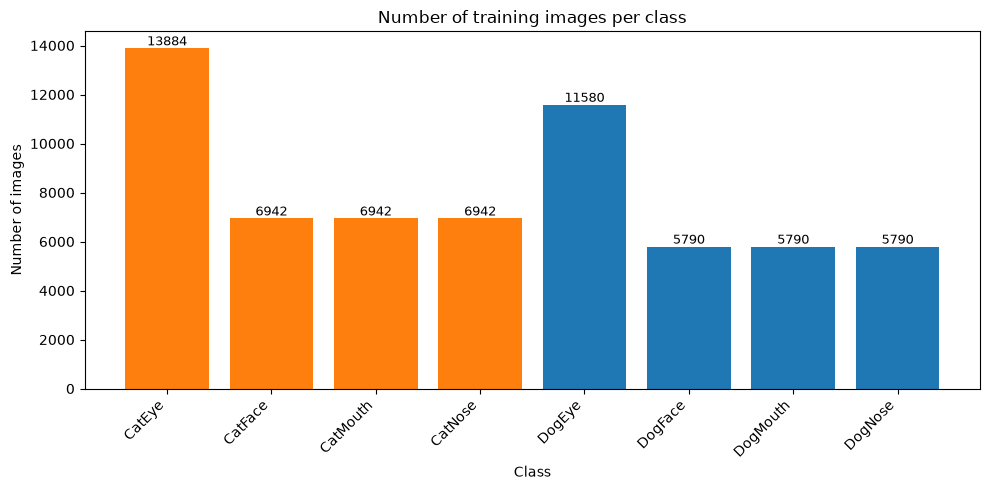

In [11]:
# Bar chart of class counts. Cat classes and dog classes get different colours.
bar_colours = []
for class_name in class_counts.index:
    if class_name.startswith("Cat"):
        bar_colours.append("tab:orange")
    else:
        bar_colours.append("tab:blue")

plt.figure(figsize=(10, 5))
bars = plt.bar(class_counts.index, class_counts.values, color=bar_colours)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, str(int(height)), ha="center", va="bottom", fontsize=9)
plt.title("Number of training images per class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
save_figure("class_distribution.png")
plt.show()

In [12]:
# Split each class name into species ("Cat"/"Dog") and part ("Eye"/"Face"/"Mouth"/"Nose")
train_df["species"] = train_df["class"].str[:3]
train_df["part"] = train_df["class"].str[3:]

species_part_table = pd.crosstab(train_df["species"], train_df["part"], margins=True)
print("Images by species and facial part:")
print(species_part_table)
print()

# Ratio of eye images to face images for each species
for species in ["Cat", "Dog"]:
    eye_count = species_part_table.loc[species, "Eye"]
    face_count = species_part_table.loc[species, "Face"]
    print(species, ": eye images / face images =", round(eye_count / face_count, 3))

species_part_table.to_csv(os.path.join(OUTPUT_DIR, "species_part_counts.csv"))

Images by species and facial part:
part       Eye   Face  Mouth   Nose    All
species                                   
Cat      13884   6942   6942   6942  34710
Dog      11580   5790   5790   5790  28950
All      25464  12732  12732  12732  63660

Cat : eye images / face images = 2.0
Dog : eye images / face images = 2.0


### 1.5 Sample images from each class

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\sample_images_per_class.png


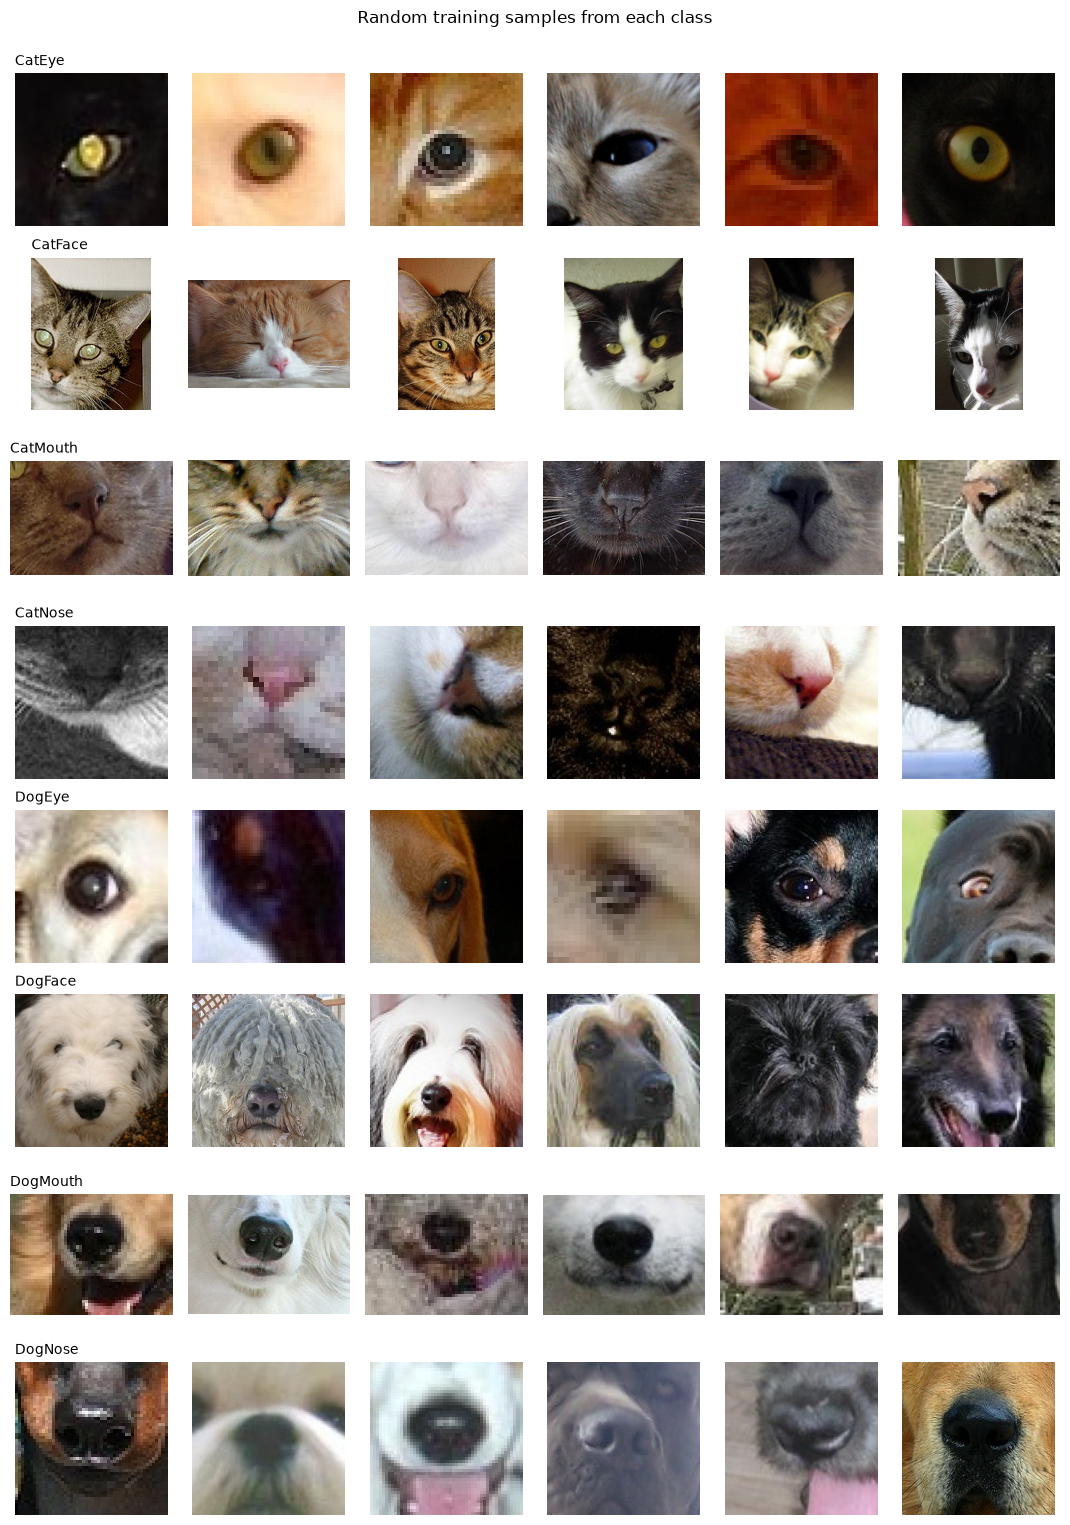

In [13]:
CLASS_NAMES_FOR_DISPLAY = sorted(train_df["class"].unique())
SAMPLES_PER_CLASS = 6

figure, axes = plt.subplots(len(CLASS_NAMES_FOR_DISPLAY), SAMPLES_PER_CLASS,
                            figsize=(SAMPLES_PER_CLASS * 1.8, len(CLASS_NAMES_FOR_DISPLAY) * 1.9))

for row_number, class_name in enumerate(CLASS_NAMES_FOR_DISPLAY):
    class_rows = train_df[train_df["class"] == class_name]
    sample_rows = class_rows.sample(n=min(SAMPLES_PER_CLASS, len(class_rows)), random_state=SEED)
    for column_number in range(SAMPLES_PER_CLASS):
        axis = axes[row_number, column_number]
        axis.axis("off")
        if column_number < len(sample_rows):
            image_path = sample_rows.iloc[column_number]["path"]
            try:
                image = Image.open(image_path).convert("RGB")
                axis.imshow(image)
            except Exception:
                axis.text(0.5, 0.5, "unreadable", ha="center", va="center")
        if column_number == 0:
            axis.set_title(class_name, fontsize=10, loc="left")

plt.suptitle("Random training samples from each class", y=1.0)
plt.tight_layout()
save_figure("sample_images_per_class.png")
plt.show()

### 1.6 Image properties and corrupted files
Every image is opened and fully decoded. This records its size, colour mode, file format and file size, and finds any file that cannot be read. For training images an MD5 hash of the file is also stored, which is used to find exact duplicates in 1.7. Test images are only checked for size and readability.

In [14]:
def survey_images(image_paths, compute_hash):
    rows = []
    start_time = time.time()
    for position, image_path in enumerate(image_paths):
        row = {"width": np.nan, "height": np.nan, "mode": None, "format": None,
               "file_kb": np.nan, "md5": None, "readable": True, "error": None}
        try:
            with open(image_path, "rb") as file:
                file_bytes = file.read()
            row["file_kb"] = len(file_bytes) / 1024
            if compute_hash:
                row["md5"] = hashlib.md5(file_bytes).hexdigest()
            image = Image.open(io.BytesIO(file_bytes))
            row["format"] = image.format
            row["mode"] = image.mode
            row["width"] = image.size[0]
            row["height"] = image.size[1]
            image.load()   # a full decode. Corrupted or truncated files fail here.
        except Exception as error:
            row["readable"] = False
            row["error"] = str(error)
        rows.append(row)
        if (position + 1) % 10000 == 0:
            print("  checked", position + 1, "images in", round(time.time() - start_time), "s")
    return pd.DataFrame(rows)


print("Checking training images...")
train_survey = survey_images(train_df["path"].tolist(), compute_hash=True)
for column_name in ["width", "height", "mode", "format", "file_kb", "md5", "readable", "error"]:
    train_df[column_name] = train_survey[column_name].values

print("Checking test images...")
test_survey = survey_images(test_df["path"].tolist(), compute_hash=False)
for column_name in ["width", "height", "mode", "format", "file_kb", "readable", "error"]:
    test_df[column_name] = test_survey[column_name].values

print()
print("Unreadable training images:", (~train_df["readable"]).sum())
print("Unreadable test images    :", (~test_df["readable"]).sum())
if (~train_df["readable"]).sum() > 0:
    print(train_df[~train_df["readable"]][["image_id", "class", "error"]].head(10))

Checking training images...
  checked 10000 images in 7 s
  checked 20000 images in 20 s
  checked 30000 images in 31 s
  checked 40000 images in 43 s
  checked 50000 images in 54 s
  checked 60000 images in 64 s
Checking test images...
  checked 10000 images in 11 s
  checked 20000 images in 20 s

Unreadable training images: 0
Unreadable test images    : 0


In [15]:
def describe_image_properties(data_frame, name):
    readable_rows = data_frame[data_frame["readable"]]
    print("=====", name, "=====")
    print("Width  : min", int(readable_rows["width"].min()), " median", int(readable_rows["width"].median()),
          " max", int(readable_rows["width"].max()))
    print("Height : min", int(readable_rows["height"].min()), " median", int(readable_rows["height"].median()),
          " max", int(readable_rows["height"].max()))
    print("Number of different (width, height) sizes:", readable_rows.groupby(["width", "height"]).ngroups)
    aspect_ratio = readable_rows["width"] / readable_rows["height"]
    print("Aspect ratio (width/height): min", round(aspect_ratio.min(), 2), " max", round(aspect_ratio.max(), 2))
    print("Colour modes :", readable_rows["mode"].value_counts().to_dict())
    print("File formats :", readable_rows["format"].value_counts().to_dict())
    print("File size KB : min", round(readable_rows["file_kb"].min(), 1), " median",
          round(readable_rows["file_kb"].median(), 1), " max", round(readable_rows["file_kb"].max(), 1))
    print("Most common sizes:")
    print(readable_rows.groupby(["width", "height"]).size().sort_values(ascending=False).head(5))
    print()


describe_image_properties(train_df, "Training images")
describe_image_properties(test_df, "Test images")

# Size per class (are some classes stored at different sizes?)
size_by_class = train_df[train_df["readable"]].groupby("class")[["width", "height", "file_kb"]].median()
print("Median size per class:")
print(size_by_class)
size_by_class.to_csv(os.path.join(OUTPUT_DIR, "image_size_by_class.csv"))

===== Training images =====
Width  : min 4  median 84  max 2219
Height : min 4  median 80  max 2219
Number of different (width, height) sizes: 7861
Aspect ratio (width/height): min 0.4  max 10.0
Colour modes : {'RGB': 63660}
File formats : {'JPEG': 63660}
File size KB : min 0.6  median 4.2  max 1233.1
Most common sizes:
width  height
40     40        1062
48     48        1051
42     42        1050
44     44        1002
38     38        1002
dtype: int64

===== Test images =====
Width  : min 8  median 82  max 1832
Height : min 9  median 80  max 1978
Number of different (width, height) sizes: 7786
Aspect ratio (width/height): min 0.3  max 4.44
Colour modes : {'RGB': 29443}
File formats : {'JPEG': 29443}
File size KB : min 0.7  median 4.1  max 1176.0
Most common sizes:
width  height
40     40        503
50     50        402
80     80        370
30     30        349
60     60        343
dtype: int64

Median size per class:
          width  height    file_kb
class                          

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\image_size_histograms.png


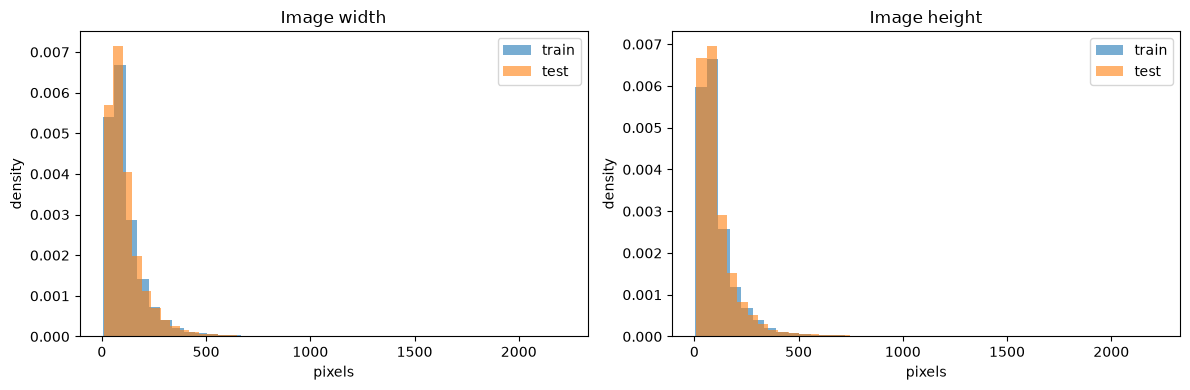

In [16]:
# Histograms of image width and height, training against test
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df["width"].dropna(), bins=40, alpha=0.6, label="train", density=True)
axes[0].hist(test_df["width"].dropna(), bins=40, alpha=0.6, label="test", density=True)
axes[0].set_title("Image width")
axes[0].set_xlabel("pixels")
axes[0].set_ylabel("density")
axes[0].legend()

axes[1].hist(train_df["height"].dropna(), bins=40, alpha=0.6, label="train", density=True)
axes[1].hist(test_df["height"].dropna(), bins=40, alpha=0.6, label="test", density=True)
axes[1].set_title("Image height")
axes[1].set_xlabel("pixels")
axes[1].set_ylabel("density")
axes[1].legend()

plt.tight_layout()
save_figure("image_size_histograms.png")
plt.show()

### 1.7 Duplicate images in the training set
Two files with the same MD5 hash are byte-for-byte identical. Duplicates matter for two reasons. If the copies land in both the training and validation sets, validation accuracy is inflated. If the copies carry different labels, at least one label is wrong.

In [17]:
readable_train = train_df[train_df["readable"]]
hash_counts = readable_train["md5"].value_counts()
duplicated_hashes = hash_counts[hash_counts > 1].index.tolist()

duplicate_rows = readable_train[readable_train["md5"].isin(duplicated_hashes)].sort_values("md5")
print("Groups of identical images:", len(duplicated_hashes))
print("Training rows inside those groups:", len(duplicate_rows))

# Look for groups where the identical images have different labels
labels_per_group = duplicate_rows.groupby("md5")["class"].nunique()
conflicting_hashes = []
for file_hash in labels_per_group.index:
    if labels_per_group[file_hash] > 1:
        conflicting_hashes.append(file_hash)

print("Groups with conflicting labels:", len(conflicting_hashes))
if len(duplicate_rows) > 0:
    print()
    print(duplicate_rows[["image_id", "class", "md5"]].head(20))
    duplicate_rows[["image_id", "class", "md5"]].to_csv(os.path.join(OUTPUT_DIR, "duplicate_training_images.csv"), index=False)

Groups of identical images: 15
Training rows inside those groups: 30
Groups with conflicting labels: 0

      image_id     class                               md5
50178    50179    DogEye  247d3453f39160cedf8572152a469614
30200    30201    DogEye  247d3453f39160cedf8572152a469614
3925     03926    CatEye  2ef198d0dbc74c0275d2c25e99ca9b41
56007    56008    CatEye  2ef198d0dbc74c0275d2c25e99ca9b41
49149    49150    DogEye  318bf3dc8990978cd4cec09a4a93dacc
55760    55761    DogEye  318bf3dc8990978cd4cec09a4a93dacc
55964    55965   DogFace  43860826259a3f526b8491670edd167c
35038    35039   DogFace  43860826259a3f526b8491670edd167c
45624    45625   DogFace  4828e68f4d594c27524f04bf0b890e86
54077    54078   DogFace  4828e68f4d594c27524f04bf0b890e86
7218     07219  CatMouth  5074d0a42b4af07fa66d9b5e21a0e38e
12149    12150  CatMouth  5074d0a42b4af07fa66d9b5e21a0e38e
16729    16730    CatEye  79c9a49563635accf70d232667966da4
21959    21960    CatEye  79c9a49563635accf70d232667966da4
42279    42

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\duplicate_examples.png


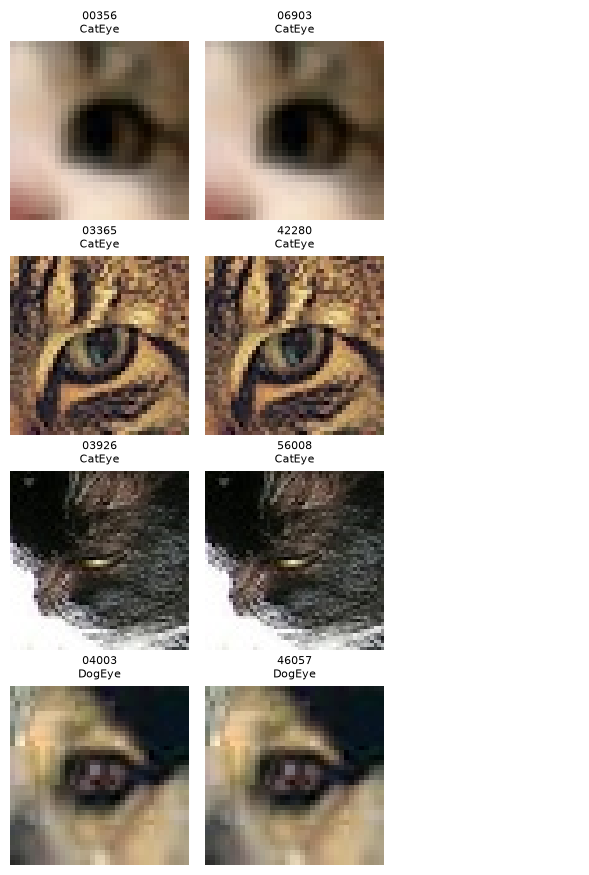

In [18]:
# Show up to 4 duplicate groups so they can be checked by eye
groups_to_show = duplicated_hashes[:4]
if len(groups_to_show) > 0:
    figure, axes = plt.subplots(len(groups_to_show), 3, figsize=(6, 2.2 * len(groups_to_show)), squeeze=False)
    for row_number, file_hash in enumerate(groups_to_show):
        group_rows = readable_train[readable_train["md5"] == file_hash]
        for column_number in range(3):
            axis = axes[row_number, column_number]
            axis.axis("off")
            if column_number < len(group_rows):
                group_row = group_rows.iloc[column_number]
                axis.imshow(Image.open(group_row["path"]).convert("RGB"))
                axis.set_title(group_row["image_id"] + "\n" + group_row["class"], fontsize=8)
    plt.tight_layout()
    save_figure("duplicate_examples.png")
    plt.show()
else:
    print("No exact duplicates found.")

### 1.8 Blurry images
A common sharpness measure is the variance of the Laplacian. The Laplacian highlights edges, so a sharp image gives a high variance and a blurry image gives a low one. Each image is first converted to greyscale and resized to 128 x 128, so the scores are comparable between images of different sizes. This is run on a random sample of 3,000 training images to save time.

In [19]:
def laplacian_variance(image_path):
    image = Image.open(image_path).convert("L").resize((128, 128))
    pixels = np.asarray(image, dtype=np.float32)
    # Discrete Laplacian: up + down + left + right - 4 x centre
    laplacian = (pixels[:-2, 1:-1] + pixels[2:, 1:-1] + pixels[1:-1, :-2] + pixels[1:-1, 2:]
                 - 4 * pixels[1:-1, 1:-1])
    return float(laplacian.var())


blur_sample = readable_train.sample(n=min(3000, len(readable_train)), random_state=SEED).copy()
blur_scores = []
for image_path in blur_sample["path"]:
    blur_scores.append(laplacian_variance(image_path))
blur_sample["blur_score"] = blur_scores

print("Sharpness score (variance of Laplacian), lower = blurrier")
print(blur_sample["blur_score"].describe().round(1))
print()
print("Median sharpness score per class:")
print(blur_sample.groupby("class")["blur_score"].median().round(1))
blur_sample[["image_id", "class", "blur_score"]].to_csv(os.path.join(OUTPUT_DIR, "blur_scores_sample.csv"), index=False)

Sharpness score (variance of Laplacian), lower = blurrier
count     3000.0
mean       628.8
std       1041.6
min          1.8
25%         45.0
50%        202.8
75%        740.0
max      11659.7
Name: blur_score, dtype: float64

Median sharpness score per class:
class
CatEye       162.0
CatFace     1026.3
CatMouth     402.8
CatNose       96.7
DogEye        54.4
DogFace      657.4
DogMouth     186.3
DogNose       57.8
Name: blur_score, dtype: float64


Saved figure: c:\Kaggle-Competition\outputs_run2\figures\blur_histogram.png


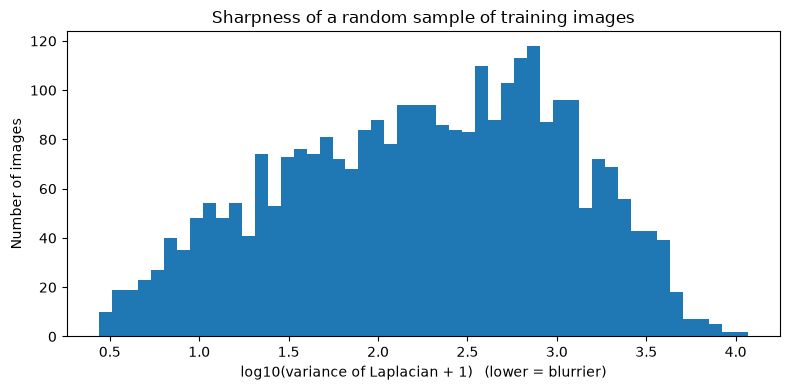

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\blurriest_images.png


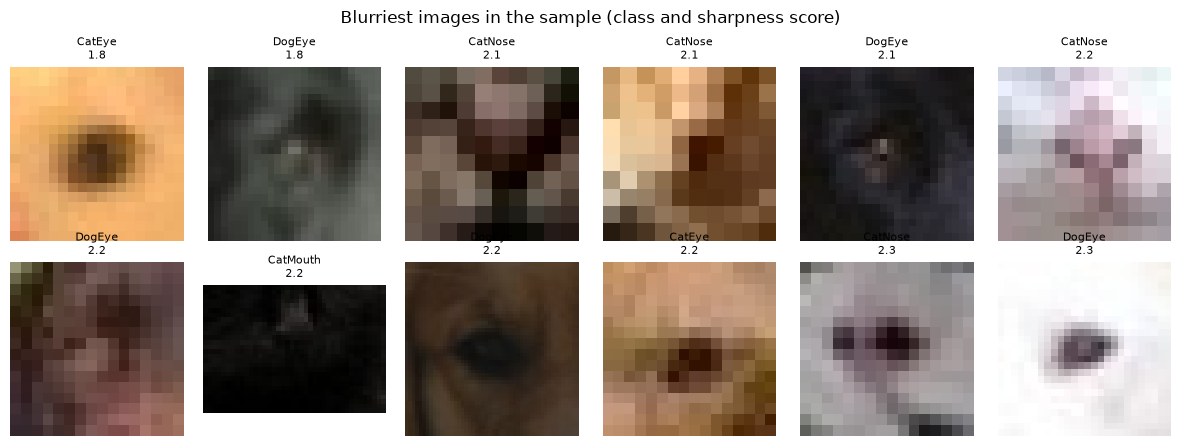

In [20]:
plt.figure(figsize=(8, 4))
plt.hist(np.log10(blur_sample["blur_score"] + 1), bins=50)
plt.title("Sharpness of a random sample of training images")
plt.xlabel("log10(variance of Laplacian + 1)   (lower = blurrier)")
plt.ylabel("Number of images")
plt.tight_layout()
save_figure("blur_histogram.png")
plt.show()

# The 12 blurriest images in the sample
blurriest = blur_sample.sort_values("blur_score").head(12)
figure, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for position in range(12):
    axis = axes[position // 6, position % 6]
    axis.axis("off")
    if position < len(blurriest):
        blur_row = blurriest.iloc[position]
        axis.imshow(Image.open(blur_row["path"]).convert("RGB"))
        axis.set_title(blur_row["class"] + "\n" + str(round(blur_row["blur_score"], 1)), fontsize=8)
plt.suptitle("Blurriest images in the sample (class and sharpness score)")
plt.tight_layout()
save_figure("blurriest_images.png")
plt.show()

### 1.9 Clean-up decisions
Unreadable training images are removed, because they would crash training. Identical images with conflicting labels are removed when `DROP_CONFLICTING_DUPLICATES` is True, because there is no way to know which label is right. Identical images with the same label are kept, but section 2.2 makes sure every copy goes into the same split.

In [21]:
rows_before = len(train_df)

train_df = train_df[train_df["readable"]].reset_index(drop=True)
print("Removed unreadable training images:", rows_before - len(train_df))

if DROP_CONFLICTING_DUPLICATES and len(conflicting_hashes) > 0:
    rows_before_conflict = len(train_df)
    train_df = train_df[~train_df["md5"].isin(conflicting_hashes)].reset_index(drop=True)
    print("Removed images with conflicting duplicate labels:", rows_before_conflict - len(train_df))

print("Training images remaining:", len(train_df))

Removed unreadable training images: 0
Training images remaining: 63660


## 2. Data preprocessing and pipeline preparation (Task 2)

### 2.1 Label encoding
Each class name is mapped to a number from 0 to 7, because the loss function needs integer labels. The mapping is saved so predictions can be turned back into names.

In [22]:
EXPECTED_CLASS_NAMES = ["CatEye", "CatFace", "CatMouth", "CatNose", "DogEye", "DogFace", "DogMouth", "DogNose"]

CLASS_NAMES = sorted(train_df["class"].unique())
NUMBER_OF_CLASSES = len(CLASS_NAMES)

# Safety check: the labels must match the official names exactly (singular "Eye", not "Eyes")
if CLASS_NAMES != EXPECTED_CLASS_NAMES:
    print("WARNING: class names differ from the expected list:", CLASS_NAMES)

class_to_index = {}
index_to_class = {}
for index, class_name in enumerate(CLASS_NAMES):
    class_to_index[class_name] = index
    index_to_class[index] = class_name

label_numbers = []
for class_name in train_df["class"]:
    label_numbers.append(class_to_index[class_name])
train_df["label"] = label_numbers

print("Label encoding:")
for class_name in CLASS_NAMES:
    print("  ", class_to_index[class_name], "->", class_name)

with open(os.path.join(OUTPUT_DIR, "class_to_index.json"), "w") as file:
    json.dump(class_to_index, file, indent=2)

Label encoding:
   0 -> CatEye
   1 -> CatFace
   2 -> CatMouth
   3 -> CatNose
   4 -> DogEye
   5 -> DogFace
   6 -> DogMouth
   7 -> DogNose


### 2.2 Stratified train/validation split
Each class is shuffled with a fixed seed and 20% of it goes to validation. Splitting class by class keeps the class proportions the same in both sets. The classes are not equal in size (eye classes are larger), so this matters.

After the split, any validation image that has an identical copy in the training set is moved into the training set. This stops exact duplicates leaking between the two sets.

Note: the CSV has no ID for the original animal face. Crops from the same face (for example its two eyes) can therefore still end up on both sides of the split. The test set is unseen, so this cannot be fully removed with the data provided.

In [23]:
random_generator = np.random.default_rng(SEED)

train_parts = []
validation_parts = []
for class_name in CLASS_NAMES:
    class_rows = train_df[train_df["class"] == class_name]
    shuffled_positions = random_generator.permutation(len(class_rows))
    number_for_validation = int(round(len(class_rows) * VALIDATION_FRACTION))
    validation_positions = shuffled_positions[:number_for_validation]
    training_positions = shuffled_positions[number_for_validation:]
    validation_parts.append(class_rows.iloc[validation_positions])
    train_parts.append(class_rows.iloc[training_positions])

train_split_df = pd.concat(train_parts).reset_index(drop=True)
validation_split_df = pd.concat(validation_parts).reset_index(drop=True)

# Move validation images that are exact copies of a training image into the training set
training_hashes = set(train_split_df["md5"])
leaking_rows = validation_split_df["md5"].isin(training_hashes)
print("Validation images with an identical copy in training (moved to training):", leaking_rows.sum())
train_split_df = pd.concat([train_split_df, validation_split_df[leaking_rows]]).reset_index(drop=True)
validation_split_df = validation_split_df[~leaking_rows].reset_index(drop=True)

# Checks
overlap_ids = set(train_split_df["image_id"]) & set(validation_split_df["image_id"])
overlap_hashes = set(train_split_df["md5"]) & set(validation_split_df["md5"])
print("Image IDs in both sets   :", len(overlap_ids))
print("Identical files in both  :", len(overlap_hashes))
print("Training images          :", len(train_split_df))
print("Validation images        :", len(validation_split_df))
print()

split_table = pd.DataFrame({
    "train": train_split_df["class"].value_counts().sort_index(),
    "validation": validation_split_df["class"].value_counts().sort_index(),
})
split_table["validation_percent"] = (100 * split_table["validation"] / (split_table["train"] + split_table["validation"])).round(1)
print(split_table)

# Save the split so it can be reproduced exactly
train_split_df[["image_id", "class", "label"]].to_csv(os.path.join(OUTPUT_DIR, "split_train.csv"), index=False)
validation_split_df[["image_id", "class", "label"]].to_csv(os.path.join(OUTPUT_DIR, "split_validation.csv"), index=False)
split_table.to_csv(os.path.join(OUTPUT_DIR, "split_class_counts.csv"))

Validation images with an identical copy in training (moved to training): 5
Image IDs in both sets   : 0
Identical files in both  : 0
Training images          : 50934
Validation images        : 12726

          train  validation  validation_percent
class                                          
CatEye    11110        2774                20.0
CatFace    5554        1388                20.0
CatMouth   5554        1388                20.0
CatNose    5554        1388                20.0
DogEye     9265        2315                20.0
DogFace    4633        1157                20.0
DogMouth   4632        1158                20.0
DogNose    4632        1158                20.0


### 2.3 Image transforms (resize, augmentation, normalisation)
There are two transform pipelines.

The **training** pipeline adds random changes so the model sees a slightly different version of each image every epoch. This reduces overfitting. Horizontal flips are safe, because a mirrored eye or nose is still the same class. Vertical flips are not used, because upside-down faces do not occur in the data. Rotation, cropping and colour changes are kept small so the feature stays recognisable.

The **evaluation** pipeline is used for validation and test images. It only resizes and normalises, so evaluation is consistent and repeatable.

Both pipelines normalise with the ImageNet mean and standard deviation, because the pretrained models expect inputs on that scale. `ToTensor` first rescales pixels from 0-255 to 0-1.

In [24]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# RUN 2: one new augmentation, based on the run 1 error analysis.
# Most of run 1's mistakes were tiny, blurry crops. Blurring a quarter of the training images
# on purpose teaches the model to recognise features that have lost their fine detail.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.80, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=9, sigma=(0.5, 3.0))], p=0.25),   # RUN 2: new
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Validation and test images are processed exactly as in run 1
evaluation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Training transform:")
print(train_transform)
print()
print("Evaluation transform (validation and test):")
print(evaluation_transform)

Training transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.02, 0.02))
    RandomApply(
    p=0.25
    GaussianBlur(kernel_size=(9, 9), sigma=(0.5, 3.0))
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Evaluation transform (validation and test):
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### 2.4 Dataset class and data loaders
The `Dataset` class reads one image from disk, converts it to RGB (so greyscale or RGBA files become 3 channels), applies the transform and returns it with its label. Test images have no label, so they get -1.

The `DataLoader` groups images into batches and loads them in parallel. Only the training loader is shuffled.

In [25]:
# RUN 2: images are now loaded by several worker processes in parallel, so the GPU is not left waiting.
# On Windows, those worker processes cannot see a class typed into a notebook cell. They can only
# import it from a .py file. So this cell writes the Dataset class below into facial_dataset.py,
# in the same folder as the outputs folder, and imports it from there.
import sys
import importlib

dataset_module_code = """
from PIL import Image
from torch.utils.data import Dataset


class FacialFeatureDataset(Dataset):
    def __init__(self, image_paths, labels, transform, fallback_size):
        self.image_paths = list(image_paths)
        self.labels = list(labels)
        self.transform = transform
        self.fallback_size = fallback_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        try:
            image = Image.open(image_path).convert("RGB")
        except Exception:
            # Should not happen for training data (unreadable files were removed in 1.9).
            # A test image still needs a prediction, so a black image is used instead.
            print("Warning: could not read", image_path, "- using a black image")
            image = Image.new("RGB", (self.fallback_size, self.fallback_size))
        image_tensor = self.transform(image)
        label = self.labels[index]
        return image_tensor, label
"""

MODULE_FOLDER = os.getcwd()
module_path = os.path.join(MODULE_FOLDER, "facial_dataset.py")
with open(module_path, "w") as file:
    file.write(dataset_module_code)
print("Dataset class saved to", module_path)

if MODULE_FOLDER not in sys.path:
    sys.path.insert(0, MODULE_FOLDER)
import facial_dataset
importlib.reload(facial_dataset)   # reloads the file if this cell is run a second time
FacialFeatureDataset = facial_dataset.FacialFeatureDataset

train_dataset = FacialFeatureDataset(train_split_df["path"], train_split_df["label"], train_transform, IMAGE_SIZE)
validation_dataset = FacialFeatureDataset(validation_split_df["path"], validation_split_df["label"], evaluation_transform, IMAGE_SIZE)
test_dataset = FacialFeatureDataset(test_df["path"], [-1] * len(test_df), evaluation_transform, IMAGE_SIZE)

pin_memory = device.type == "cuda"


def make_data_loaders(number_of_workers):
    # A seeded generator makes the training shuffle order repeatable
    loader_generator = torch.Generator()
    loader_generator.manual_seed(SEED)

    keep_workers_alive = number_of_workers > 0
    if number_of_workers > 0:
        seconds_before_giving_up = 300   # stops the notebook hanging forever if a worker gets stuck
    else:
        seconds_before_giving_up = 0

    new_train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=number_of_workers,
                                  pin_memory=pin_memory, persistent_workers=keep_workers_alive,
                                  generator=loader_generator, timeout=seconds_before_giving_up)
    new_validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
                                       num_workers=number_of_workers, pin_memory=pin_memory,
                                       persistent_workers=keep_workers_alive, timeout=seconds_before_giving_up)
    new_test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
                                 num_workers=number_of_workers, pin_memory=pin_memory,
                                 persistent_workers=keep_workers_alive, timeout=seconds_before_giving_up)
    return new_train_loader, new_validation_loader, new_test_loader


train_loader, validation_loader, test_loader = make_data_loaders(NUM_WORKERS)

# Check that parallel loading works on this computer. If it does not, load in the main process instead.
if NUM_WORKERS > 0:
    print("Starting", NUM_WORKERS, "image-loading worker processes (the first start can take up to a minute)...")
    try:
        check_images, check_labels = next(iter(validation_loader))
        print("Parallel image loading works.")
    except Exception as error:
        print("Parallel image loading did not work on this computer:", error)
        print("Switching to loading images in the main process. This is slower but always works.")
        NUM_WORKERS = 0
        train_loader, validation_loader, test_loader = make_data_loaders(0)

print("Image-loading workers       :", NUM_WORKERS)
print("Training batches per epoch  :", len(train_loader))
print("Validation batches          :", len(validation_loader))
print("Test batches                :", len(test_loader))

Dataset class saved to c:\Kaggle-Competition\facial_dataset.py
Image-loading workers       : 0
Training batches per epoch  : 1592
Validation batches          : 199
Test batches                : 461


### 2.5 Check one batch
This confirms the tensor shapes and value range, and shows what the augmented training images look like.

Batch of images shape: (32, 3, 224, 224)  (batch, channels, height, width)
Batch of labels shape: (32,)
Pixel values after normalisation: min -2.12  max 2.64  mean -0.27
Saved figure: c:\Kaggle-Competition\outputs_run2\figures\augmented_batch.png


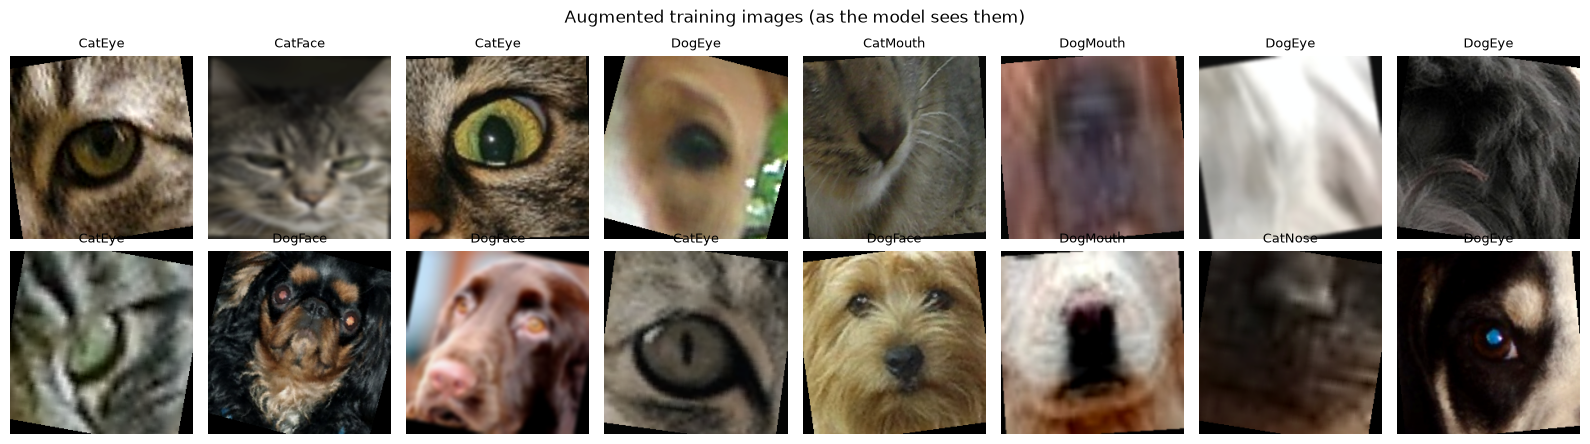

In [26]:
def tensor_to_display_image(image_tensor):
    # Undo the normalisation so the image can be shown
    image = image_tensor.cpu().numpy().transpose(1, 2, 0)   # (channels, height, width) -> (height, width, channels)
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    image = np.clip(image, 0, 1)
    return image


example_images, example_labels = next(iter(train_loader))
print("Batch of images shape:", tuple(example_images.shape), " (batch, channels, height, width)")
print("Batch of labels shape:", tuple(example_labels.shape))
print("Pixel values after normalisation: min", round(example_images.min().item(), 2),
      " max", round(example_images.max().item(), 2), " mean", round(example_images.mean().item(), 2))

figure, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for position in range(16):
    axis = axes[position // 8, position % 8]
    axis.axis("off")
    if position < len(example_images):
        axis.imshow(tensor_to_display_image(example_images[position]))
        axis.set_title(index_to_class[int(example_labels[position])], fontsize=9)
plt.suptitle("Augmented training images (as the model sees them)")
plt.tight_layout()
save_figure("augmented_batch.png")
plt.show()

## 3. Model selection and pipeline development (Task 3)

Two kinds of model are built.

1. **Main model: transfer learning with EfficientNet-B0** (Tan and Le, 2019), pretrained on ImageNet. Its original 1000-class output layer is replaced with a dropout layer and a new linear layer with 8 outputs.
2. **Baseline: a small CNN trained from scratch.** This gives a reference point, so the benefit of transfer learning can be measured.

`resnet50` and `convnext_tiny` are also available through `MODEL_NAME` if you want to compare architectures.

The output layer gives 8 raw scores (logits). `nn.CrossEntropyLoss` applies softmax internally during training. At prediction time softmax is applied explicitly to turn the scores into probabilities.

In [27]:
class CustomCNN(nn.Module):
    # Four convolution blocks. Each block: Conv -> BatchNorm -> ReLU -> Conv -> BatchNorm -> ReLU -> MaxPool.
    # The number of filters doubles each block (32, 64, 128, 256) while the image size halves.
    def __init__(self, number_of_classes):
        super().__init__()
        self.features = nn.Sequential(
            self.make_block(3, 32),
            self.make_block(32, 64),
            self.make_block(64, 128),
            self.make_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)          # average each feature map down to one number
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(256, number_of_classes),
        )

    def make_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

In [28]:
def build_model(model_name, number_of_classes, use_pretrained):
    if model_name == "custom_cnn":
        return CustomCNN(number_of_classes)

    try:
        if model_name == "efficientnet_b0":
            weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if use_pretrained else None
            model = models.efficientnet_b0(weights=weights)
            number_of_features = model.classifier[1].in_features     # 1280
            model.classifier = nn.Sequential(
                nn.Dropout(p=DROPOUT_RATE),
                nn.Linear(number_of_features, number_of_classes),
            )
        elif model_name == "resnet50":
            weights = models.ResNet50_Weights.IMAGENET1K_V2 if use_pretrained else None
            model = models.resnet50(weights=weights)
            number_of_features = model.fc.in_features                # 2048
            model.fc = nn.Sequential(
                nn.Dropout(p=DROPOUT_RATE),
                nn.Linear(number_of_features, number_of_classes),
            )
        elif model_name == "convnext_tiny":
            weights = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if use_pretrained else None
            model = models.convnext_tiny(weights=weights)
            number_of_features = model.classifier[2].in_features     # 768
            model.classifier[2] = nn.Sequential(
                nn.Dropout(p=DROPOUT_RATE),
                nn.Linear(number_of_features, number_of_classes),
            )
        else:
            raise ValueError("Unknown model name: " + model_name)
    except (OSError, RuntimeError) as error:
        print("Could not download the pretrained weights. Check the internet connection (on Kaggle, turn Internet on in the settings panel).")
        raise error
    return model


def get_head(model, model_name):
    # The "head" is the new final layer(s). Everything else is the "backbone".
    if model_name == "resnet50":
        return model.fc
    return model.classifier


def set_backbone_trainable(model, model_name, trainable):
    # Freeze or unfreeze every layer, then always keep the head trainable
    for parameter in model.parameters():
        parameter.requires_grad = trainable
    for parameter in get_head(model, model_name).parameters():
        parameter.requires_grad = True


def count_parameters(model):
    total = 0
    trainable = 0
    for parameter in model.parameters():
        total = total + parameter.numel()
        if parameter.requires_grad:
            trainable = trainable + parameter.numel()
    return total, trainable

In [29]:
# Inspect the main model before training
inspection_model = build_model(MODEL_NAME, NUMBER_OF_CLASSES, USE_PRETRAINED)
total_parameters, trainable_parameters = count_parameters(inspection_model)
print("Model:", MODEL_NAME, " pretrained:", USE_PRETRAINED)
print("Total parameters:", f"{total_parameters:,}")
print()
print("New classification head:")
print(get_head(inspection_model, MODEL_NAME))

set_backbone_trainable(inspection_model, MODEL_NAME, trainable=False)
total_parameters, trainable_parameters = count_parameters(inspection_model)
print()
print("Trainable parameters with the backbone frozen:", f"{trainable_parameters:,}")

# Pass a dummy batch through to confirm the input and output shapes
inspection_model.eval()
with torch.no_grad():
    dummy_input = torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE)
    dummy_output = inspection_model(dummy_input)
print("Input shape :", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape), " (batch, number of classes)")

baseline_model_for_count = CustomCNN(NUMBER_OF_CLASSES)
print()
print("Baseline CustomCNN parameters:", f"{count_parameters(baseline_model_for_count)[0]:,}")
del inspection_model, baseline_model_for_count

Model: convnext_tiny  pretrained: True
Total parameters: 27,826,280

New classification head:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=768, out_features=8, bias=True)
  )
)

Trainable parameters with the backbone frozen: 7,688
Input shape : (2, 3, 224, 224)
Output shape: (2, 8)  (batch, number of classes)

Baseline CustomCNN parameters: 1,175,272


## 4. Training strategy and overfitting/underfitting management (Task 4)

### 4.1 Training and evaluation functions
One epoch of training does the following for every batch: forward pass, loss, backpropagation, weight update. Loss and accuracy are recorded.

Note: training accuracy is measured on augmented images with dropout switched on. Validation accuracy uses clean images with dropout off. Keep this in mind when comparing the two curves.

In [30]:
def make_grad_scaler(enabled):
    # The gradient scaler is needed for mixed precision. It does nothing when disabled.
    # torch.amp.GradScaler is the newer name. Older PyTorch versions only have torch.cuda.amp.GradScaler.
    if hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=enabled)
    return torch.cuda.amp.GradScaler(enabled=enabled)


def train_one_epoch(model, data_loader, loss_function, optimiser, scaler):
    model.train()   # switches dropout and batch-norm to training behaviour
    total_loss = 0.0
    total_correct = 0
    total_images = 0
    number_of_batches = len(data_loader)
    epoch_start_time = time.time()

    for batch_number, (images, labels) in enumerate(data_loader, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimiser.zero_grad()

        # Forward pass (in 16-bit on the GPU if mixed precision is on)
        with torch.autocast(device_type=device.type, enabled=use_mixed_precision):
            outputs = model(images)
            loss = loss_function(outputs, labels)

        # Backward pass and weight update
        scaler.scale(loss).backward()
        scaler.step(optimiser)
        scaler.update()

        batch_size = labels.size(0)
        total_loss = total_loss + loss.item() * batch_size
        predictions = outputs.argmax(dim=1)
        total_correct = total_correct + (predictions == labels).sum().item()
        total_images = total_images + batch_size

        # Progress report, so a long epoch does not look frozen
        if PRINT_EVERY_BATCHES > 0 and batch_number % PRINT_EVERY_BATCHES == 0:
            seconds_so_far = time.time() - epoch_start_time
            seconds_per_batch = seconds_so_far / batch_number
            seconds_left = seconds_per_batch * (number_of_batches - batch_number)
            print(f"    batch {batch_number}/{number_of_batches} | loss so far {total_loss / total_images:.4f} | "
                  f"{seconds_so_far / 60:.1f} min done, about {seconds_left / 60:.1f} min left in this epoch")

    average_loss = total_loss / total_images
    accuracy = total_correct / total_images
    return average_loss, accuracy


def evaluate(model, data_loader, loss_function):
    model.eval()    # switches dropout off and uses the stored batch-norm statistics
    total_loss = 0.0
    total_correct = 0
    total_images = 0

    with torch.no_grad():   # no gradients are needed, which saves memory and time
        for images, labels in data_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_mixed_precision):
                outputs = model(images)
                loss = loss_function(outputs, labels)
            batch_size = labels.size(0)
            total_loss = total_loss + loss.item() * batch_size
            predictions = outputs.argmax(dim=1)
            total_correct = total_correct + (predictions == labels).sum().item()
            total_images = total_images + batch_size

    average_loss = total_loss / total_images
    accuracy = total_correct / total_images
    return average_loss, accuracy

### 4.2 Experiment runner
Each experiment is a list of stages. Each stage has its own number of epochs, learning rate and frozen/unfrozen setting.

- **Optimiser:** AdamW. It adapts the step size for each weight and applies weight decay correctly.
- **Learning-rate schedule:** cosine annealing. The learning rate starts at the stage value and falls smoothly towards zero by the last epoch of the stage.
- **Checkpointing:** the weights with the lowest validation loss so far are saved. These best weights are used for evaluation and prediction, not the weights from the last epoch.
- **Early stopping:** a stage ends early if validation loss has not improved for `EARLY_STOPPING_PATIENCE` epochs.

In [31]:
def run_experiment(experiment):
    print("=" * 90)
    print("Experiment:", experiment["name"], " | model:", experiment["model_name"], " | pretrained:", experiment["pretrained"])
    print("=" * 90)

    set_seed(SEED)   # every experiment starts from the same random state
    model = build_model(experiment["model_name"], NUMBER_OF_CLASSES, experiment["pretrained"])
    model = model.to(device)

    loss_function = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    checkpoint_path = os.path.join(OUTPUT_DIR, experiment["name"] + "_best.pth")

    history_rows = []
    best_validation_loss = float("inf")
    best_validation_accuracy = 0.0
    best_epoch = 0
    epoch_counter = 0
    experiment_start_time = time.time()

    for stage in experiment["stages"]:
        if stage["epochs"] <= 0:
            continue
        print("--- Stage:", stage["stage"], "|", stage["epochs"], "epochs | learning rate", stage["learning_rate"],
              "| backbone frozen:", stage["freeze_backbone"], "---")

        set_backbone_trainable(model, experiment["model_name"], trainable=not stage["freeze_backbone"])
        parameters_to_train = []
        for parameter in model.parameters():
            if parameter.requires_grad:
                parameters_to_train.append(parameter)
        total_parameters, trainable_parameters = count_parameters(model)
        print("Trainable parameters in this stage:", f"{trainable_parameters:,}", "of", f"{total_parameters:,}")

        optimiser = torch.optim.AdamW(parameters_to_train, lr=stage["learning_rate"], weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=stage["epochs"])
        scaler = make_grad_scaler(use_mixed_precision)
        epochs_without_improvement = 0

        for stage_epoch in range(1, stage["epochs"] + 1):
            epoch_counter = epoch_counter + 1
            epoch_start_time = time.time()
            current_learning_rate = optimiser.param_groups[0]["lr"]

            train_loss, train_accuracy = train_one_epoch(model, train_loader, loss_function, optimiser, scaler)
            validation_loss, validation_accuracy = evaluate(model, validation_loader, loss_function)
            scheduler.step()

            epoch_seconds = time.time() - epoch_start_time
            history_rows.append({
                "experiment": experiment["name"],
                "stage": stage["stage"],
                "epoch": epoch_counter,
                "learning_rate": current_learning_rate,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "validation_loss": validation_loss,
                "validation_accuracy": validation_accuracy,
                "seconds": epoch_seconds,
            })
            print(f"Epoch {epoch_counter:2d} | lr {current_learning_rate:.1e} | "
                  f"train loss {train_loss:.4f} acc {train_accuracy:.4f} | "
                  f"val loss {validation_loss:.4f} acc {validation_accuracy:.4f} | {epoch_seconds:.0f} s")

            if validation_loss < best_validation_loss:
                best_validation_loss = validation_loss
                best_validation_accuracy = validation_accuracy
                best_epoch = epoch_counter
                torch.save(model.state_dict(), checkpoint_path)
                epochs_without_improvement = 0
                print("        new best validation loss, checkpoint saved")
            else:
                epochs_without_improvement = epochs_without_improvement + 1
                if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                    print("        early stopping: no improvement for", EARLY_STOPPING_PATIENCE, "epochs")
                    break

    total_minutes = (time.time() - experiment_start_time) / 60
    history_df = pd.DataFrame(history_rows)
    history_df.to_csv(os.path.join(OUTPUT_DIR, "history_" + experiment["name"] + ".csv"), index=False)

    total_parameters, trainable_parameters = count_parameters(model)
    result = {
        "experiment": experiment["name"],
        "model": experiment["model_name"],
        "pretrained": experiment["pretrained"],
        "parameters": total_parameters,
        "epochs_run": epoch_counter,
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "validation_accuracy_at_best": best_validation_accuracy,
        "training_minutes": total_minutes,
        "checkpoint": checkpoint_path,
    }
    print("Finished in", round(total_minutes, 1), "minutes. Best epoch:", best_epoch,
          "| val loss", round(best_validation_loss, 4), "| val acc", round(best_validation_accuracy, 4))
    return model, history_df, result

### 4.3 Define and run the experiments
- **A_custom_cnn:** the baseline CNN trained from random weights in one stage.
- **B_transfer_learning:** the pretrained model in two stages. Stage 1 freezes the backbone and trains only the new head. This lets the randomly initialised head settle before the pretrained weights are touched. Stage 2 unfreezes everything and fine-tunes with a smaller learning rate.

Model B is the final model used for the submission.

In [32]:
experiments = []

if RUN_BASELINE_CNN:
    experiments.append({
        "name": "A_custom_cnn",
        "model_name": "custom_cnn",
        "pretrained": False,
        "stages": [
            {"stage": "full_training", "epochs": BASELINE_EPOCHS, "learning_rate": BASELINE_LEARNING_RATE, "freeze_backbone": False},
        ],
    })

experiments.append({
    "name": "B_transfer_learning",
    "model_name": MODEL_NAME,
    "pretrained": USE_PRETRAINED,
    "stages": [
        {"stage": "head_only", "epochs": HEAD_ONLY_EPOCHS, "learning_rate": HEAD_LEARNING_RATE, "freeze_backbone": True},
        {"stage": "fine_tune", "epochs": FINE_TUNE_EPOCHS, "learning_rate": FINE_TUNE_LEARNING_RATE, "freeze_backbone": False},
    ],
})

FINAL_EXPERIMENT_NAME = "B_transfer_learning"

all_histories = {}
all_results = []

if USE_SAVED_MODEL:
    # RUN 2: training already finished before the notebook was restarted. While training,
    # run_experiment saved three files in OUTPUT_DIR: the best model (.pth), the history of
    # every epoch (history_....csv) and the results table (experiment_results.csv).
    # These files are loaded here instead of training again.
    saved_results_path = os.path.join(OUTPUT_DIR, "experiment_results.csv")
    if not os.path.exists(saved_results_path):
        raise FileNotFoundError("No saved results found: " + saved_results_path +
                                ". Set USE_SAVED_MODEL = False in cell 0.3 to train from scratch.")
    saved_results_df = pd.read_csv(saved_results_path)

    for experiment in experiments:
        checkpoint_path = os.path.join(OUTPUT_DIR, experiment["name"] + "_best.pth")
        history_path = os.path.join(OUTPUT_DIR, "history_" + experiment["name"] + ".csv")
        for needed_file in [checkpoint_path, history_path]:
            if not os.path.exists(needed_file):
                raise FileNotFoundError("Saved file not found: " + needed_file +
                                        ". Set USE_SAVED_MODEL = False in cell 0.3 to train from scratch.")

        history_df = pd.read_csv(history_path)
        all_histories[experiment["name"]] = history_df

        matching_rows = saved_results_df[saved_results_df["experiment"] == experiment["name"]]
        if len(matching_rows) != 1:
            raise ValueError("experiment_results.csv has no single row for " + experiment["name"])
        result = matching_rows.iloc[0].to_dict()
        all_results.append(result)

        print("=" * 90)
        print("Loaded the saved training of", experiment["name"], "(no training was run)")
        print("Model file:", checkpoint_path)
        print("=" * 90)
        print(history_df.round(4).to_string(index=False))
        print("Training took", round(result["training_minutes"], 1), "minutes. Best epoch:", result["best_epoch"],
              "| val loss", round(result["best_validation_loss"], 4), "| val acc", round(result["validation_accuracy_at_best"], 4))
        print()
else:
    for experiment in experiments:
        trained_model, history_df, result = run_experiment(experiment)
        all_histories[experiment["name"]] = history_df
        all_results.append(result)
        # Free GPU memory before the next experiment
        del trained_model
        if device.type == "cuda":
            torch.cuda.empty_cache()

results_df = pd.DataFrame(all_results)
results_df.to_csv(os.path.join(OUTPUT_DIR, "experiment_results.csv"), index=False)
print()
print(results_df[["experiment", "model", "parameters", "epochs_run", "best_epoch",
                  "best_validation_loss", "validation_accuracy_at_best", "training_minutes"]])

Loaded the saved training of B_transfer_learning (no training was run)
Model file: c:\Kaggle-Competition\outputs_run2\B_transfer_learning_best.pth
         experiment     stage  epoch  learning_rate  train_loss  train_accuracy  validation_loss  validation_accuracy  seconds
B_transfer_learning head_only      1         0.0010      0.8104          0.8750           0.6926               0.9261 160.8988
B_transfer_learning fine_tune      2         0.0001      0.5510          0.9723           0.4941               0.9908 256.1844
B_transfer_learning fine_tune      3         0.0001      0.5045          0.9867           0.5071               0.9851 233.9432
B_transfer_learning fine_tune      4         0.0001      0.4934          0.9907           0.4925               0.9891 284.1364
B_transfer_learning fine_tune      5         0.0001      0.4863          0.9930           0.4852               0.9925 233.4430
B_transfer_learning fine_tune      6         0.0000      0.4805          0.9957           0

### 4.4 Learning curves
Training and validation loss and accuracy for each experiment. The dashed line marks where stage 1 (frozen backbone) ends and fine-tuning begins.

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\learning_curves_B_transfer_learning.png


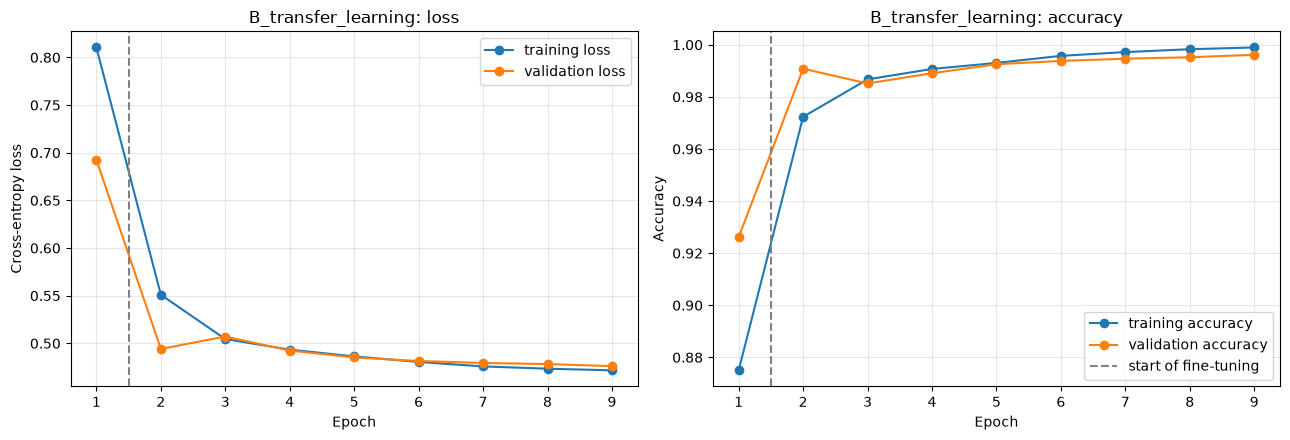

In [33]:
for experiment_name in all_histories:
    history_df = all_histories[experiment_name]
    epochs = history_df["epoch"]

    figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(epochs, history_df["train_loss"], marker="o", label="training loss")
    axes[0].plot(epochs, history_df["validation_loss"], marker="o", label="validation loss")
    axes[0].set_title(experiment_name + ": loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")

    axes[1].plot(epochs, history_df["train_accuracy"], marker="o", label="training accuracy")
    axes[1].plot(epochs, history_df["validation_accuracy"], marker="o", label="validation accuracy")
    axes[1].set_title(experiment_name + ": accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")

    # Mark the boundary between stages
    for position in range(1, len(history_df)):
        if history_df["stage"].iloc[position] != history_df["stage"].iloc[position - 1]:
            boundary = history_df["epoch"].iloc[position] - 0.5
            axes[0].axvline(boundary, color="grey", linestyle="--")
            axes[1].axvline(boundary, color="grey", linestyle="--", label="start of fine-tuning")

    axes[0].legend()
    axes[1].legend()
    axes[0].grid(alpha=0.3)
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    save_figure("learning_curves_" + experiment_name + ".png")
    plt.show()

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\validation_accuracy_comparison.png


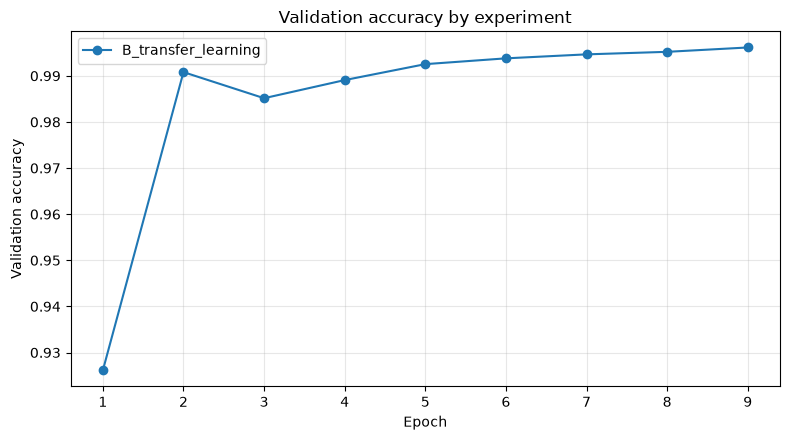

In [34]:
# All experiments on one plot: validation accuracy per epoch
plt.figure(figsize=(8, 4.5))
for experiment_name in all_histories:
    history_df = all_histories[experiment_name]
    plt.plot(history_df["epoch"], history_df["validation_accuracy"], marker="o", label=experiment_name)
plt.title("Validation accuracy by experiment")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
save_figure("validation_accuracy_comparison.png")
plt.show()

### 4.5 Generalisation gap per epoch
The gap between training and validation results, epoch by epoch. Use this table with the learning curves when discussing overfitting and underfitting.

In [35]:
gap_tables = []
for experiment_name in all_histories:
    history_df = all_histories[experiment_name].copy()
    history_df["accuracy_gap (train - val)"] = (history_df["train_accuracy"] - history_df["validation_accuracy"]).round(4)
    history_df["loss_gap (val - train)"] = (history_df["validation_loss"] - history_df["train_loss"]).round(4)
    gap_tables.append(history_df[["experiment", "stage", "epoch", "train_accuracy", "validation_accuracy",
                                  "accuracy_gap (train - val)", "train_loss", "validation_loss", "loss_gap (val - train)"]])

gap_table = pd.concat(gap_tables).reset_index(drop=True)
pd.set_option("display.width", 200)
print(gap_table.round(4).to_string(index=False))
gap_table.to_csv(os.path.join(OUTPUT_DIR, "generalisation_gap.csv"), index=False)

# Best validation accuracy reached in each stage
stage_rows = []
for experiment_name in all_histories:
    history_df = all_histories[experiment_name]
    for stage_name in history_df["stage"].unique():
        stage_history = history_df[history_df["stage"] == stage_name]
        stage_rows.append({
            "experiment": experiment_name,
            "stage": stage_name,
            "epochs": len(stage_history),
            "best_validation_accuracy": stage_history["validation_accuracy"].max(),
            "lowest_validation_loss": stage_history["validation_loss"].min(),
        })
stage_summary = pd.DataFrame(stage_rows)
print()
print(stage_summary.round(4).to_string(index=False))
stage_summary.to_csv(os.path.join(OUTPUT_DIR, "stage_summary.csv"), index=False)

         experiment     stage  epoch  train_accuracy  validation_accuracy  accuracy_gap (train - val)  train_loss  validation_loss  loss_gap (val - train)
B_transfer_learning head_only      1          0.8750               0.9261                     -0.0511      0.8104           0.6926                 -0.1178
B_transfer_learning fine_tune      2          0.9723               0.9908                     -0.0185      0.5510           0.4941                 -0.0568
B_transfer_learning fine_tune      3          0.9867               0.9851                      0.0016      0.5045           0.5071                  0.0027
B_transfer_learning fine_tune      4          0.9907               0.9891                      0.0016      0.4934           0.4925                 -0.0009
B_transfer_learning fine_tune      5          0.9930               0.9925                      0.0005      0.4863           0.4852                 -0.0012
B_transfer_learning fine_tune      6          0.9957               0.9

## 5. Model evaluation and Kaggle submission (Task 5)

### 5.1 Load the best checkpoint of the final model

In [36]:
final_experiment = None
for experiment in experiments:
    if experiment["name"] == FINAL_EXPERIMENT_NAME:
        final_experiment = experiment

final_checkpoint = os.path.join(OUTPUT_DIR, FINAL_EXPERIMENT_NAME + "_best.pth")
final_model = build_model(final_experiment["model_name"], NUMBER_OF_CLASSES, use_pretrained=False)
final_model.load_state_dict(torch.load(final_checkpoint, map_location=device))
final_model = final_model.to(device)
final_model.eval()
print("Loaded:", final_checkpoint)

Loaded: c:\Kaggle-Competition\outputs_run2\B_transfer_learning_best.pth


In [37]:
def predict_probabilities(model, data_loader, use_tta):
    # Returns an array of shape (number of images, number of classes) with softmax probabilities.
    # With TTA, each image and its horizontal mirror are both predicted and the probabilities averaged.
    model.eval()
    all_probabilities = []
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_mixed_precision):
                outputs = model(images)
            probabilities = torch.softmax(outputs.float(), dim=1)

            if use_tta:
                flipped_images = torch.flip(images, dims=[3])   # dimension 3 is the image width
                with torch.autocast(device_type=device.type, enabled=use_mixed_precision):
                    flipped_outputs = model(flipped_images)
                flipped_probabilities = torch.softmax(flipped_outputs.float(), dim=1)
                probabilities = (probabilities + flipped_probabilities) / 2

            all_probabilities.append(probabilities.cpu().numpy())
    return np.concatenate(all_probabilities, axis=0)


validation_true = validation_split_df["label"].to_numpy()

validation_probabilities_plain = predict_probabilities(final_model, validation_loader, use_tta=False)
validation_predictions_plain = validation_probabilities_plain.argmax(axis=1)
accuracy_plain = (validation_predictions_plain == validation_true).mean()

validation_probabilities_tta = predict_probabilities(final_model, validation_loader, use_tta=True)
validation_predictions_tta = validation_probabilities_tta.argmax(axis=1)
accuracy_tta = (validation_predictions_tta == validation_true).mean()

# Cross-entropy loss on the validation set, calculated directly from the probabilities
true_class_probabilities = validation_probabilities_plain[np.arange(len(validation_true)), validation_true]
validation_loss_final = float(np.mean(-np.log(np.clip(true_class_probabilities, 1e-12, 1.0))))

print("Validation loss (no TTA)    :", round(validation_loss_final, 4))
print("Validation accuracy (no TTA):", round(accuracy_plain, 4))
print("Validation accuracy (TTA)   :", round(accuracy_tta, 4))

# Use the TTA setting from the settings cell for everything that follows
if USE_TTA:
    validation_probabilities = validation_probabilities_tta
else:
    validation_probabilities = validation_probabilities_plain
validation_predictions = validation_probabilities.argmax(axis=1)
validation_accuracy_final = (validation_predictions == validation_true).mean()
print("Validation accuracy used for reporting:", round(validation_accuracy_final, 4), "(TTA on)" if USE_TTA else "(TTA off)")

Validation loss (no TTA)    : 0.0931
Validation accuracy (no TTA): 0.9961
Validation accuracy (TTA)   : 0.9965
Validation accuracy used for reporting: 0.9965 (TTA on)


### 5.2 Confusion matrix and per-class metrics
The confusion matrix has true classes as rows and predicted classes as columns. From it:

- **Precision** = correct predictions of a class / all predictions of that class
- **Recall** = correct predictions of a class / all true images of that class (this is also the class-level accuracy)
- **F1-score** = 2 x precision x recall / (precision + recall)

The macro average treats each class equally. The weighted average weights each class by its number of images.

In [38]:
confusion = np.zeros((NUMBER_OF_CLASSES, NUMBER_OF_CLASSES), dtype=int)
for true_label, predicted_label in zip(validation_true, validation_predictions):
    confusion[true_label, predicted_label] = confusion[true_label, predicted_label] + 1

metric_rows = []
for class_index in range(NUMBER_OF_CLASSES):
    true_positives = confusion[class_index, class_index]
    predicted_as_class = confusion[:, class_index].sum()
    actually_class = confusion[class_index, :].sum()

    precision = true_positives / predicted_as_class if predicted_as_class > 0 else 0.0
    recall = true_positives / actually_class if actually_class > 0 else 0.0
    if precision + recall > 0:
        f1_score = 2 * precision * recall / (precision + recall)
    else:
        f1_score = 0.0

    metric_rows.append({
        "class": index_to_class[class_index],
        "precision": precision,
        "recall (class accuracy)": recall,
        "f1_score": f1_score,
        "support": actually_class,
    })

metrics_df = pd.DataFrame(metric_rows)

supports = metrics_df["support"].to_numpy()
macro_row = {"class": "macro average", "support": supports.sum()}
weighted_row = {"class": "weighted average", "support": supports.sum()}
for column_name in ["precision", "recall (class accuracy)", "f1_score"]:
    macro_row[column_name] = metrics_df[column_name].mean()
    weighted_row[column_name] = (metrics_df[column_name] * supports).sum() / supports.sum()
metrics_df = pd.concat([metrics_df, pd.DataFrame([macro_row, weighted_row])]).reset_index(drop=True)

print("Overall validation accuracy:", round(validation_accuracy_final, 4))
print()
print(metrics_df.round(4).to_string(index=False))
metrics_df.to_csv(os.path.join(OUTPUT_DIR, "validation_classification_report.csv"), index=False)

confusion_df = pd.DataFrame(confusion, index=CLASS_NAMES, columns=CLASS_NAMES)
confusion_df.to_csv(os.path.join(OUTPUT_DIR, "validation_confusion_matrix.csv"))

Overall validation accuracy: 0.9965

           class  precision  recall (class accuracy)  f1_score  support
          CatEye     0.9971                   0.9968    0.9969     2774
         CatFace     1.0000                   1.0000    1.0000     1388
        CatMouth     0.9872                   0.9971    0.9921     1388
         CatNose     0.9949                   0.9841    0.9895     1388
          DogEye     0.9970                   0.9965    0.9968     2315
         DogFace     1.0000                   1.0000    1.0000     1157
        DogMouth     1.0000                   0.9991    0.9996     1158
         DogNose     0.9957                   0.9991    0.9974     1158
   macro average     0.9965                   0.9966    0.9965    12726
weighted average     0.9965                   0.9965    0.9965    12726


Saved figure: c:\Kaggle-Competition\outputs_run2\figures\confusion_matrix_counts.png


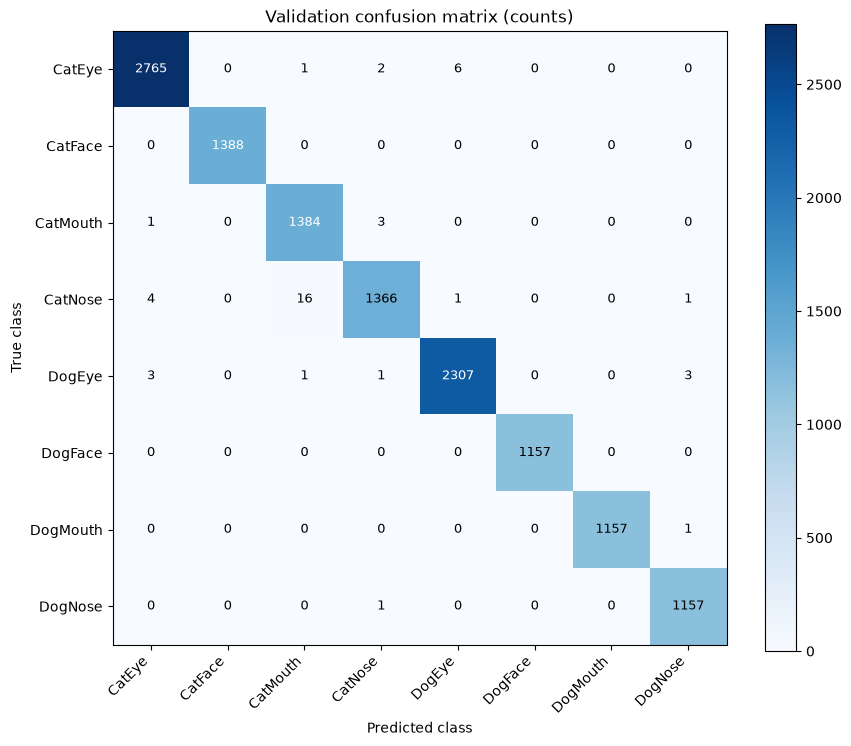

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\confusion_matrix_normalised.png


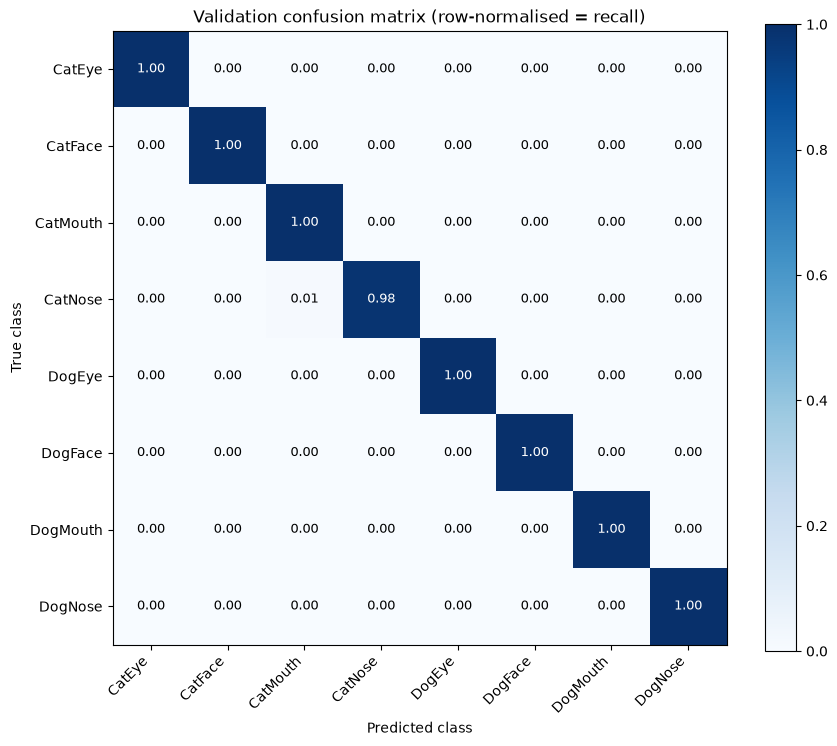

In [39]:
def plot_confusion_matrix(matrix, class_names, title, file_name, normalise):
    if normalise:
        row_totals = matrix.sum(axis=1, keepdims=True)
        values = matrix / np.maximum(row_totals, 1)
    else:
        values = matrix

    figure, axis = plt.subplots(figsize=(9, 7.5))
    picture = axis.imshow(values, cmap="Blues")
    figure.colorbar(picture, ax=axis)
    axis.set_xticks(range(len(class_names)))
    axis.set_yticks(range(len(class_names)))
    axis.set_xticklabels(class_names, rotation=45, ha="right")
    axis.set_yticklabels(class_names)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("True class")
    axis.set_title(title)

    threshold = values.max() / 2
    for row in range(len(class_names)):
        for column in range(len(class_names)):
            if normalise:
                text = f"{values[row, column]:.2f}"
            else:
                text = str(int(values[row, column]))
            text_colour = "white" if values[row, column] > threshold else "black"
            axis.text(column, row, text, ha="center", va="center", color=text_colour, fontsize=9)

    plt.tight_layout()
    save_figure(file_name)
    plt.show()


plot_confusion_matrix(confusion, CLASS_NAMES, "Validation confusion matrix (counts)", "confusion_matrix_counts.png", normalise=False)
plot_confusion_matrix(confusion, CLASS_NAMES, "Validation confusion matrix (row-normalised = recall)", "confusion_matrix_normalised.png", normalise=True)

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\per_class_metrics.png


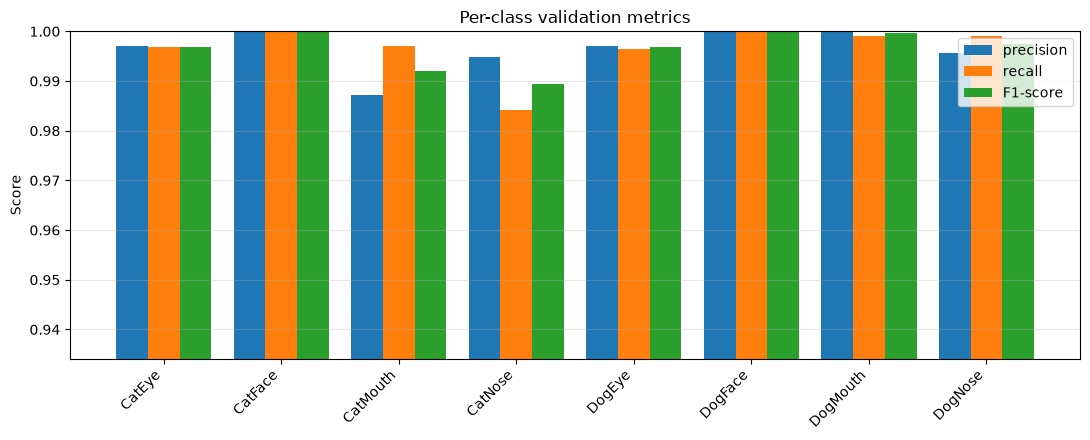

In [40]:
# Per-class precision, recall and F1 as a grouped bar chart
per_class = metrics_df[metrics_df["class"].isin(CLASS_NAMES)]
positions = np.arange(len(per_class))
bar_width = 0.27

plt.figure(figsize=(11, 4.5))
plt.bar(positions - bar_width, per_class["precision"], width=bar_width, label="precision")
plt.bar(positions, per_class["recall (class accuracy)"], width=bar_width, label="recall")
plt.bar(positions + bar_width, per_class["f1_score"], width=bar_width, label="F1-score")
plt.xticks(positions, per_class["class"], rotation=45, ha="right")
lowest_value = min(per_class["precision"].min(), per_class["recall (class accuracy)"].min(), per_class["f1_score"].min())
plt.ylim(max(0.0, lowest_value - 0.05), 1.0)
plt.ylabel("Score")
plt.title("Per-class validation metrics")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_figure("per_class_metrics.png")
plt.show()

In [41]:
# Save every validation prediction, for error analysis in the report
validation_predicted_names = []
for index in validation_predictions:
    validation_predicted_names.append(index_to_class[int(index)])

validation_results_df = pd.DataFrame({
    "image_id": validation_split_df["image_id"],
    "true_class": validation_split_df["class"],
    "predicted_class": validation_predicted_names,
    "confidence": validation_probabilities.max(axis=1),
    "correct": validation_predictions == validation_true,
})
validation_results_df.to_csv(os.path.join(OUTPUT_DIR, "validation_predictions.csv"), index=False)
print(validation_results_df.head())

  image_id true_class predicted_class  confidence  correct
0    06803     CatEye          CatEye    0.922628     True
1    13050     CatEye          CatEye    0.921597     True
2    46813     CatEye          CatEye    0.922429     True
3    34929     CatEye          CatEye    0.920235     True
4    11284     CatEye          CatEye    0.919744     True


### 5.3 Predict the test set and write the submission file
The image IDs are copied exactly from `sample_submission.csv`, in the same order. The class names come from the training labels, so they match the official spelling (`CatEye`, not `CatEyes`).

In [42]:
test_probabilities = predict_probabilities(final_model, test_loader, use_tta=USE_TTA)
test_predictions = test_probabilities.argmax(axis=1)

predicted_class_names = []
for index in test_predictions:
    predicted_class_names.append(index_to_class[int(index)])

submission_df = pd.DataFrame({
    "image_id": test_df["image_id"].values,
    "class": predicted_class_names,
})

if QUICK_TEST:
    submission_path = os.path.join(OUTPUT_DIR, "QUICK_TEST_DO_NOT_SUBMIT.csv")
else:
    submission_path = os.path.join(OUTPUT_DIR, "submission.csv")
submission_df.to_csv(submission_path, index=False)
print("Saved:", submission_path)
print(submission_df.head(10))

# Also keep the test probabilities (useful later for ensembling)
probability_df = pd.DataFrame(test_probabilities, columns=CLASS_NAMES)
probability_df.insert(0, "image_id", test_df["image_id"].values)
probability_df.to_csv(os.path.join(OUTPUT_DIR, "test_probabilities_" + FINAL_EXPERIMENT_NAME + ".csv"), index=False)

Saved: c:\Kaggle-Competition\outputs_run2\submission.csv
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth
5        6   DogFace
6        7  CatMouth
7        8    DogEye
8        9    CatEye
9       10   CatNose


In [43]:
# Checks on the saved file before it goes to Kaggle
saved_submission = pd.read_csv(submission_path, dtype=str)

check_columns = list(saved_submission.columns) == ["image_id", "class"]
check_no_missing = saved_submission.isna().sum().sum() == 0
check_class_names = set(saved_submission["class"]).issubset(set(EXPECTED_CLASS_NAMES))
check_ids_match = saved_submission["image_id"].tolist() == test_df["image_id"].tolist()
if QUICK_TEST:
    check_row_count = len(saved_submission) == len(test_df)
else:
    check_row_count = len(saved_submission) == len(sample_submission_df)
    check_ids_match = check_ids_match and saved_submission["image_id"].tolist() == sample_submission_df["image_id"].tolist()

print("Columns are exactly image_id, class :", check_columns)
print("Row count matches sample submission :", check_row_count, "(", len(saved_submission), "rows )")
print("Image IDs identical and same order  :", check_ids_match)
print("No missing values                   :", check_no_missing)
print("Only official class names used      :", check_class_names)

if check_columns and check_row_count and check_ids_match and check_no_missing and check_class_names:
    print()
    print("All checks passed.")
else:
    print()
    print("A CHECK FAILED. Do not submit until it is fixed.")

print()
print("Predicted class counts on the test set:")
print(saved_submission["class"].value_counts().sort_index())

Columns are exactly image_id, class : True
Row count matches sample submission : True ( 29443 rows )
Image IDs identical and same order  : True
No missing values                   : True
Only official class names used      : True

All checks passed.

Predicted class counts on the test set:
class
CatEye      6317
CatFace     3113
CatMouth    3246
CatNose     2906
DogEye      5580
DogFace     2808
DogMouth    2756
DogNose     2717
Name: count, dtype: int64


### 5.4 Validation accuracy against the Kaggle score
After submitting, type your public leaderboard score below and re-run this cell. Take a screenshot of the leaderboard and your submissions page as evidence for the report.

In [44]:
KAGGLE_PUBLIC_SCORE = None    # for example 0.9512, after you submit

print("Validation accuracy (final model):", round(validation_accuracy_final, 4))
if KAGGLE_PUBLIC_SCORE is None:
    print("Kaggle public score: not entered yet")
else:
    difference = validation_accuracy_final - KAGGLE_PUBLIC_SCORE
    print("Kaggle public score:", KAGGLE_PUBLIC_SCORE)
    print("Validation minus Kaggle:", round(difference, 4))

Validation accuracy (final model): 0.9965
Kaggle public score: not entered yet


## 6. Results analysis support (Task 6)
These cells produce the evidence for the error analysis. The interpretation is for the report.

### 6.1 Most common confusions

In [45]:
confusion_pairs = []
for true_index in range(NUMBER_OF_CLASSES):
    for predicted_index in range(NUMBER_OF_CLASSES):
        if true_index != predicted_index and confusion[true_index, predicted_index] > 0:
            confusion_pairs.append({
                "true_class": index_to_class[true_index],
                "predicted_class": index_to_class[predicted_index],
                "count": confusion[true_index, predicted_index],
                "percent_of_true_class": 100 * confusion[true_index, predicted_index] / confusion[true_index, :].sum(),
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs, columns=["true_class", "predicted_class", "count", "percent_of_true_class"])
confusion_pairs_df = confusion_pairs_df.sort_values("count", ascending=False).reset_index(drop=True)
print("Total validation errors:", int((validation_predictions != validation_true).sum()), "of", len(validation_true))
print()
print(confusion_pairs_df.head(15).round(2).to_string(index=False))
confusion_pairs_df.to_csv(os.path.join(OUTPUT_DIR, "most_confused_pairs.csv"), index=False)

Total validation errors: 45 of 12726

true_class predicted_class  count  percent_of_true_class
   CatNose        CatMouth     16                   1.15
    CatEye          DogEye      6                   0.22
   CatNose          CatEye      4                   0.29
  CatMouth         CatNose      3                   0.22
    DogEye          CatEye      3                   0.13
    DogEye         DogNose      3                   0.13
    CatEye         CatNose      2                   0.07
  CatMouth          CatEye      1                   0.07
    CatEye        CatMouth      1                   0.04
   CatNose         DogNose      1                   0.07
   CatNose          DogEye      1                   0.07
    DogEye        CatMouth      1                   0.04
    DogEye         CatNose      1                   0.04
  DogMouth         DogNose      1                   0.09
   DogNose         CatNose      1                   0.09


### 6.2 Error type: species, part, or both
Each class has two parts: a species (Cat or Dog) and a facial part (Eye, Face, Mouth or Nose). Every mistake is sorted into one of three types:
- right part, wrong species (for example CatNose predicted as DogNose)
- right species, wrong part (for example CatEye predicted as CatNose)
- both wrong

In [46]:
true_names = validation_results_df["true_class"]
predicted_names = validation_results_df["predicted_class"]

species_correct = true_names.str[:3] == predicted_names.str[:3]
part_correct = true_names.str[3:] == predicted_names.str[3:]
is_error = ~validation_results_df["correct"]

print("Species accuracy (Cat vs Dog only)      :", round(species_correct.mean(), 4))
print("Facial part accuracy (ignoring species) :", round(part_correct.mean(), 4))
print()
print("Errors with right part, wrong species :", int((is_error & part_correct & ~species_correct).sum()))
print("Errors with right species, wrong part :", int((is_error & species_correct & ~part_correct).sum()))
print("Errors with both wrong                :", int((is_error & ~species_correct & ~part_correct).sum()))

# Species accuracy for each facial part
part_rows = []
for part_name in ["Eye", "Face", "Mouth", "Nose"]:
    rows_for_part = true_names.str[3:] == part_name
    part_rows.append({
        "part": part_name,
        "images": int(rows_for_part.sum()),
        "accuracy": validation_results_df[rows_for_part]["correct"].mean(),
        "species_accuracy": species_correct[rows_for_part].mean(),
    })
part_summary = pd.DataFrame(part_rows)
print()
print(part_summary.round(4).to_string(index=False))
part_summary.to_csv(os.path.join(OUTPUT_DIR, "accuracy_by_part.csv"), index=False)

Species accuracy (Cat vs Dog only)      : 0.9989
Facial part accuracy (ignoring species) : 0.9973

Errors with right part, wrong species : 11
Errors with right species, wrong part : 31
Errors with both wrong                : 3

 part  images  accuracy  species_accuracy
  Eye    5089    0.9967            0.9978
 Face    2545    1.0000            1.0000
Mouth    2546    0.9980            1.0000
 Nose    2546    0.9910            0.9988


### 6.3 Most confident mistakes
Wrong predictions made with high confidence often show label noise, unclear crops or a real weakness of the model.

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\most_confident_mistakes.png


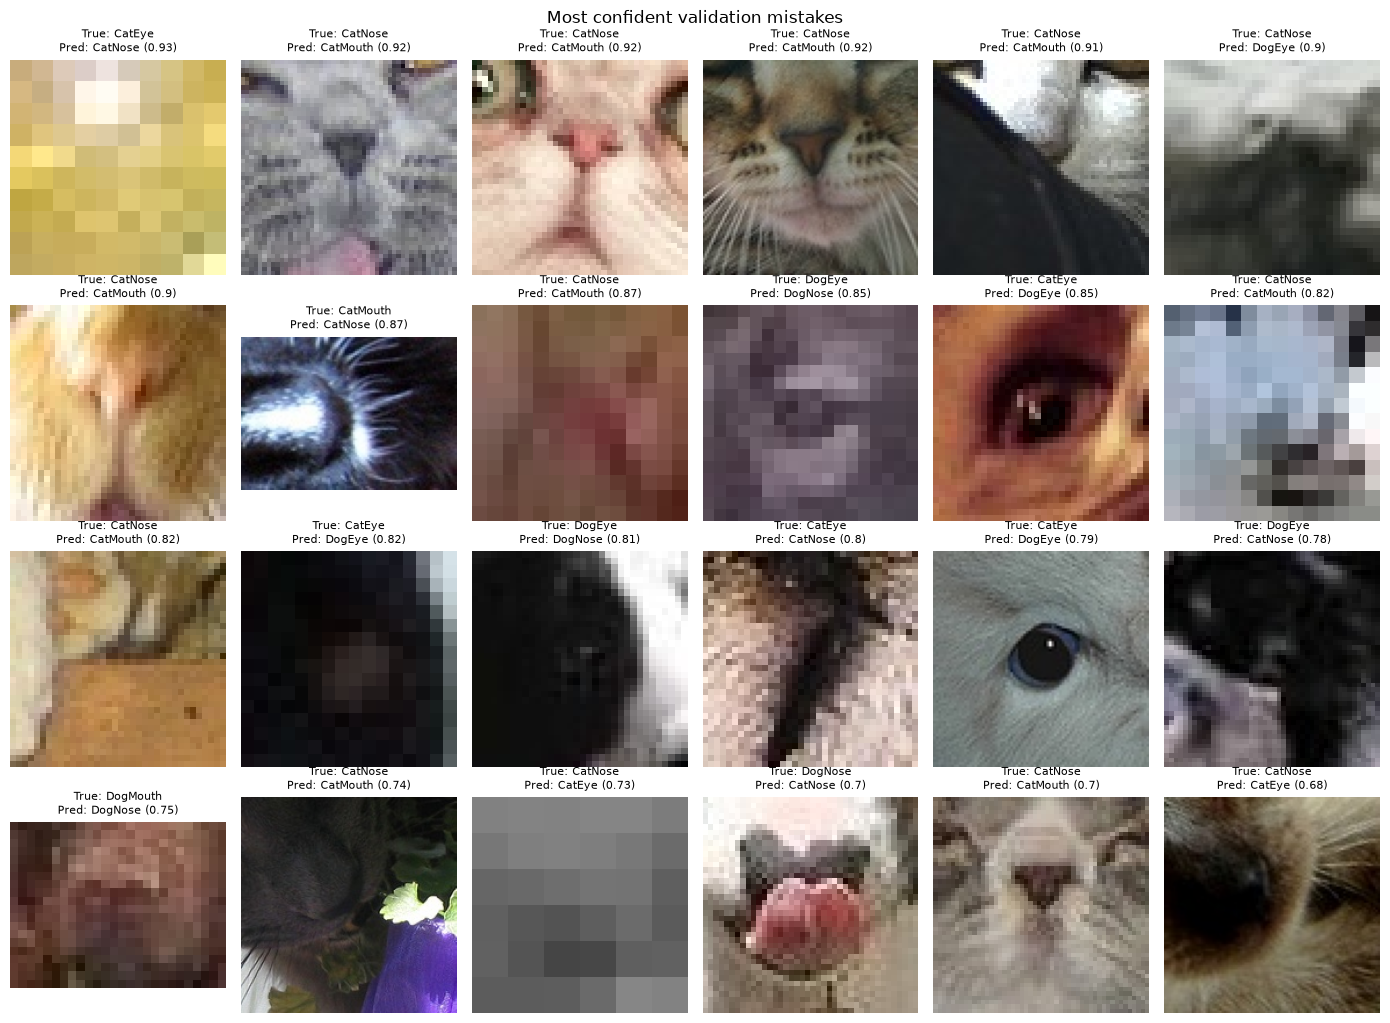

In [47]:
wrong_predictions = validation_results_df[~validation_results_df["correct"]].sort_values("confidence", ascending=False)
wrong_predictions = wrong_predictions.merge(validation_split_df[["image_id", "path"]], on="image_id", how="left")

number_to_show = min(24, len(wrong_predictions))
if number_to_show > 0:
    number_of_columns = 6
    number_of_rows = int(np.ceil(number_to_show / number_of_columns))
    figure, axes = plt.subplots(number_of_rows, number_of_columns, figsize=(14, 2.6 * number_of_rows), squeeze=False)
    for position in range(number_of_rows * number_of_columns):
        axis = axes[position // number_of_columns, position % number_of_columns]
        axis.axis("off")
        if position < number_to_show:
            mistake = wrong_predictions.iloc[position]
            axis.imshow(Image.open(mistake["path"]).convert("RGB"))
            axis.set_title("True: " + mistake["true_class"] + "\nPred: " + mistake["predicted_class"]
                           + " (" + str(round(mistake["confidence"], 2)) + ")", fontsize=8)
    plt.suptitle("Most confident validation mistakes")
    plt.tight_layout()
    save_figure("most_confident_mistakes.png")
    plt.show()
else:
    print("No validation mistakes to show.")

### 6.4 Confidence of correct and wrong predictions

Saved figure: c:\Kaggle-Competition\outputs_run2\figures\confidence_histogram.png


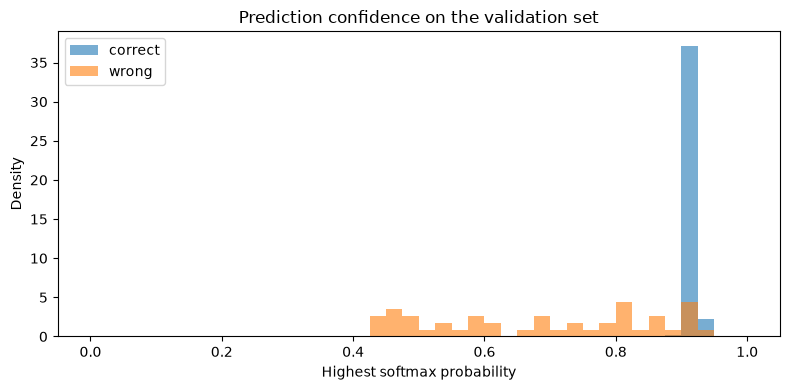

Confidence >= 0.5: 99.9% of images, accuracy 0.9972
Confidence >= 0.7: 99.6% of images, accuracy 0.9983
Confidence >= 0.9: 98.2% of images, accuracy 0.9995


In [ ]:
correct_confidence = validation_results_df[validation_results_df["correct"]]["confidence"]
wrong_confidence = validation_results_df[~validation_results_df["correct"]]["confidence"]

confidence_bins = np.linspace(0, 1, 41)   # 40 equal bins from 0 to 1

plt.figure(figsize=(8, 4))
if len(correct_confidence) > 0:
    plt.hist(correct_confidence, bins=confidence_bins, alpha=0.6, density=True, label="correct")
if len(wrong_confidence) > 0:
    plt.hist(wrong_confidence, bins=confidence_bins, alpha=0.6, density=True, label="wrong")
plt.title("Prediction confidence on the validation set")
plt.xlabel("Highest softmax probability")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
save_figure("confidence_histogram.png").
plt.show()

for threshold in [0.5, 0.7, 0.9]:
    confident_rows = validation_results_df["confidence"] >= threshold
    print(f"Confidence >= {threshold}: {confident_rows.mean() * 100:.1f}% of images, accuracy "
          f"{validation_results_df[confident_rows]['correct'].mean():.4f}")

### 6.5 Experiment comparison

In [49]:
comparison_df = results_df[["experiment", "model", "pretrained", "parameters", "epochs_run", "best_epoch",
                            "best_validation_loss", "validation_accuracy_at_best", "training_minutes"]].copy()
formatted_parameters = []
for number in comparison_df["parameters"]:
    formatted_parameters.append(f"{number:,}")
comparison_df["parameters"] = formatted_parameters
print(comparison_df.round(4).to_string(index=False))
print()
print("Final model with TTA off:", round(accuracy_plain, 4), "| with TTA on:", round(accuracy_tta, 4))
comparison_df.to_csv(os.path.join(OUTPUT_DIR, "experiment_comparison.csv"), index=False)

         experiment         model  pretrained parameters  epochs_run  best_epoch  best_validation_loss  validation_accuracy_at_best  training_minutes
B_transfer_learning convnext_tiny        True 27,826,280           9           9                0.4761                       0.9961           37.6611

Final model with TTA off: 0.9961 | with TTA on: 0.9965


## 7. Reproducibility (Task 7)
All settings and library versions are saved to `run_config.json`. Together with `split_train.csv` and `split_validation.csv`, this is enough to repeat the run.

In [50]:
run_config = {
    "seed": SEED,
    "quick_test": QUICK_TEST,
    "image_size": IMAGE_SIZE,
    "validation_fraction": VALIDATION_FRACTION,
    "batch_size": BATCH_SIZE,
    "model_name": MODEL_NAME,
    "use_pretrained": USE_PRETRAINED,
    "dropout_rate": DROPOUT_RATE,
    "head_only_epochs": HEAD_ONLY_EPOCHS,
    "head_learning_rate": HEAD_LEARNING_RATE,
    "fine_tune_epochs": FINE_TUNE_EPOCHS,
    "fine_tune_learning_rate": FINE_TUNE_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "mixed_precision": use_mixed_precision,
    "baseline_cnn": RUN_BASELINE_CNN,
    "baseline_epochs": BASELINE_EPOCHS,
    "baseline_learning_rate": BASELINE_LEARNING_RATE,
    "use_tta": USE_TTA,
    "training_images": len(train_split_df),
    "validation_images": len(validation_split_df),
    "test_images": len(test_df),
    "final_validation_accuracy": float(validation_accuracy_final),
    "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "versions": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "pillow": PIL.__version__,
        "matplotlib": matplotlib.__version__,
    },
}
with open(os.path.join(OUTPUT_DIR, "run_config.json"), "w") as file:
    json.dump(run_config, file, indent=2)

print("Files saved in", os.path.abspath(OUTPUT_DIR), ":")
for root, subfolders, files in os.walk(OUTPUT_DIR):
    for file_name in sorted(files):
        full_path = os.path.join(root, file_name)
        print("  ", os.path.relpath(full_path, OUTPUT_DIR), "-", round(os.path.getsize(full_path) / 1024, 1), "KB")

Files saved in c:\Kaggle-Competition\outputs_run2 :
   B_transfer_learning_best.pth - 108764.8 KB
   accuracy_by_part.csv - 0.2 KB
   blur_scores_sample.csv - 96.2 KB
   class_counts.csv - 0.2 KB
   class_to_index.json - 0.1 KB
   duplicate_training_images.csv - 1.4 KB
   experiment_comparison.csv - 0.2 KB
   experiment_results.csv - 0.3 KB
   generalisation_gap.csv - 1.2 KB
   history_B_transfer_learning.csv - 1.4 KB
   image_size_by_class.csv - 0.3 KB
   most_confused_pairs.csv - 0.6 KB
   run_config.json - 0.9 KB
   species_part_counts.csv - 0.1 KB
   split_class_counts.csv - 0.2 KB
   split_train.csv - 835.7 KB
   split_validation.csv - 208.8 KB
   stage_summary.csv - 0.2 KB
   submission.csv - 414.7 KB
   test_probabilities_B_transfer_learning.csv - 2894.1 KB
   validation_classification_report.csv - 0.7 KB
   validation_confusion_matrix.csv - 0.3 KB
   validation_predictions.csv - 471.5 KB
   figures\augmented_batch.png - 1442.0 KB
   figures\blur_histogram.png - 28.9 KB
   figur

## 8. Run 2: ensemble with run 1
Averages the test probabilities of run 1 (EfficientNet-B0, in the `outputs` folder) and run 2 (ConvNeXt-Tiny, in `outputs_run2`), and writes `outputs_run2/submission_ensemble.csv`.

In [ ]:
# ---------------------------------------------------------------
# RUN 2: ensemble of run 1 (EfficientNet-B0) and run 2 (ConvNeXt-Tiny)
# Averages the two models' test probabilities and writes submission_ensemble.csv.
# Run 1's results stay in the outputs folder. Run 2 saves to outputs_run2 (set in cell 0.4).
# ---------------------------------------------------------------
RUN1_FOLDER = os.path.join(os.path.dirname(OUTPUT_DIR), "outputs")
RUN1_PROBABILITIES = os.path.join(RUN1_FOLDER, "test_probabilities_B_transfer_learning.csv")
RUN2_PROBABILITIES = os.path.join(OUTPUT_DIR, "test_probabilities_B_transfer_learning.csv")
RUN2_WEIGHT = 0.5    # how much the run 2 model counts. 0.5 = both models count equally

if QUICK_TEST:
    print("Quick test mode: the ensemble is skipped, because the quick test only predicts part of the test set.")
elif not os.path.exists(RUN1_PROBABILITIES):
    print("Run 1 probabilities not found:", RUN1_PROBABILITIES)
    print("Check that run 1's files are still in the outputs folder, and that cell 0.4 saves this run to outputs_run2.")
else:
    run1_df = pd.read_csv(RUN1_PROBABILITIES, dtype={"image_id": str})
    run2_df = pd.read_csv(RUN2_PROBABILITIES, dtype={"image_id": str})

    # Both files must list the same test images in the same order
    if run1_df["image_id"].tolist() != run2_df["image_id"].tolist():
        raise ValueError("The two probability files do not list the same test images in the same order.")

    run1_probabilities = run1_df[CLASS_NAMES].to_numpy()
    run2_probabilities = run2_df[CLASS_NAMES].to_numpy()
    ensemble_probabilities = (1 - RUN2_WEIGHT) * run1_probabilities + RUN2_WEIGHT * run2_probabilities

    run1_predictions = run1_probabilities.argmax(axis=1)
    run2_predictions = run2_probabilities.argmax(axis=1)
    ensemble_predictions = ensemble_probabilities.argmax(axis=1)

    number_of_disagreements = int((run1_predictions != run2_predictions).sum())
    print("Test images where run 1 and run 2 disagree:", number_of_disagreements, "of", len(run1_predictions))
    print("Ensemble predictions that differ from run 1:", int((ensemble_predictions != run1_predictions).sum()))
    print("Ensemble predictions that differ from run 2:", int((ensemble_predictions != run2_predictions).sum()))

    ensemble_class_names = []
    for index in ensemble_predictions:
        ensemble_class_names.append(index_to_class[int(index)])

    ensemble_submission_df = pd.DataFrame({
        "image_id": run1_df["image_id"].values,
        "class": ensemble_class_names,
    })
    ensemble_path = os.path.join(OUTPUT_DIR, "submission_ensemble.csv")
    ensemble_submission_df.to_csv(ensemble_path, index=False)
    print("Saved:", ensemble_path)

    # The same checks as section 5.3, on the saved ensemble file
    saved_ensemble = pd.read_csv(ensemble_path, dtype=str)
    check_columns = list(saved_ensemble.columns) == ["image_id", "class"]
    check_row_count = len(saved_ensemble) == len(sample_submission_df)
    check_ids_match = saved_ensemble["image_id"].tolist() == sample_submission_df["image_id"].tolist()
    check_no_missing = saved_ensemble.isna().sum().sum() == 0
    check_class_names = set(saved_ensemble["class"]).issubset(set(EXPECTED_CLASS_NAMES))

    print()
    print("Columns are exactly image_id, class :", check_columns)
    print("Row count matches sample submission :", check_row_count, "(", len(saved_ensemble), "rows )")
    print("Image IDs identical and same order  :", check_ids_match)
    print("No missing values                   :", check_no_missing)
    print("Only official class names used      :", check_class_names)
    if check_columns and check_row_count and check_ids_match and check_no_missing and check_class_names:
        print()
        print("All checks passed.")
    else:
        print()
        print("A CHECK FAILED. Do not submit until it is fixed.")

Test images where run 1 and run 2 disagree: 476 of 29443
Ensemble predictions that differ from run 1: 218
Ensemble predictions that differ from run 2: 260
Saved: c:\Kaggle-Competition\outputs_run2\submission_ensemble.csv

Columns are exactly image_id, class : True
Row count matches sample submission : True ( 29443 rows )
Image IDs identical and same order  : True
No missing values                   : True
Only official class names used      : True

All checks passed.


## References
- Paszke, A., et al. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*.
- Tan, M., & Le, Q. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *Proceedings of the 36th International Conference on Machine Learning*, 6105-6114.
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, 770-778.
- Deng, J., et al. (2009). ImageNet: A large-scale hierarchical image database. *IEEE Conference on Computer Vision and Pattern Recognition*, 248-255.
- Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. *International Conference on Learning Representations*.
- Pech-Pacheco, J. L., et al. (2000). Diatom autofocusing in brightfield microscopy: A comparative study. *Proceedings of the 15th International Conference on Pattern Recognition*, 314-317. (variance of the Laplacian as a sharpness measure)
- torchvision pretrained models documentation: https://pytorch.org/vision/stable/models.html